# Figure 4: Spatial Scale of Cortical Column Similarity

This notebook only reads cached full-cohort outputs. It is intentionally not executed by the SLURM workflow.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display

ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/results/qc/"
    "full_cohort_spatial_scale"
)
PAIR_DIR = ROOT / "figure4_pairs"
REAL_DIR = ROOT / "figure4_real/cohort"
RELATIVE_MAE_DIR = ROOT / "figure4_relative_mae/cohort"
WITHIN_REGION_DIR = ROOT / "figure4_within_region"
WITHIN_WHOLE_CORTEX_DIR = ROOT / "figure4_within_region_whole_cortex"
DK_ALL_PAIRS_DIR = (
    ROOT / "figure4_dk_all_pairs_region_balanced/cohort"
)
ACQUISITION_NULL_DIR = ROOT / "figure4_acquisition_sampling_full325_fwhm0/cohort"
LONG_RANGE_DIR = ROOT / "figure4_long_range_platform_full_cohort"
LAMINAR_SHAPE_DIR = ROOT / "figure4_common_laminar_shape_pilot20"
WHOLE_PROFILE_NULL_DIR = (
    ROOT / "figure4_whole_profile_permutation_pilot20/cohort"
)
REPO_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / '.git').exists()
)
sys.path.insert(0, str(REPO_ROOT))
from qc.publication_style import (
    FIGURE_WIDTH_IN, PALETTE, save_publication_figure,
    set_publication_style, style_axes,
)

sns.set_theme(style="ticks", context="notebook")
set_publication_style()
FIGURE_DIR = ROOT / 'figures'

## 1. Scientific questions
The analysis asks how quickly 21-depth O3 MD profiles become dissimilar with white-surface geodesic distance, whether the pattern exceeds a physically interpretable acquisition-and-sampling null, whether the fitted spatial scale is reproducible, and whether DK boundaries add dissimilarity at matched distances. The primary null uses native-DWI-grid noise, a prespecified PSF family, real O3 sampling, and subject-specific laminar mean/covariance matching. The independent-component surface surrogate and the older unrecolored interpolation-only null are retained only as supplementary diagnostics.

## 2. Pair-table construction
All subjects reuse fixed fsaverage white-surface pairs. No sphere distance, inflated-surface distance, or three-dimensional Euclidean distance is used.

In [2]:
pair_inventory = pd.read_csv(PAIR_DIR / "figure4_pair_table_inventory.csv")
pair_counts = pd.read_csv(PAIR_DIR / "figure4_pair_counts.csv")
display(pair_inventory)
display(pair_counts.head())

,hemisphere,n_template_vertices,n_analysis_mask_vertices,n_anchors,n_all_pairs,n_boundary_stratified_pairs
0,lh,163842,149953,2048,612741,897020
1,rh,163842,149926,2048,612575,885818


,hemisphere,distance_bin,pair_type,n_pairs
0,lh,0-2,across_boundary,1972
1,lh,0-2,within_region,1972
2,lh,10-12,across_boundary,30032
3,lh,10-12,within_region,30032
4,lh,12-14,across_boundary,33430


## 3. Geodesic-distance and sampling QC
The independent unit is the subject. Pair-level measurements are first summarized within anchor and distance bin, then within subject.

## 4. Figure 4A: Real spatial curves

Profile dissimilarity, $1-r$, measures differences in profile shape. A complementary symmetric relative profile MAE quantifies numerical differences relative to the typical magnitude of the two profiles:

$$
\mathrm{sRMAE}_{ij}(\%) = \frac{200\,\operatorname{mean}_d|X_i(d)-X_j(d)|}{\operatorname{median}_d|X_i(d)|+\operatorname{median}_d|X_j(d)|}.
$$

Both metrics use the same fixed pairs and the hierarchy pair $\rightarrow$ anchor × distance-bin median $\rightarrow$ subject median $\rightarrow$ group median/IQR.

**Symmetric relative MAE.** 325/325 subjects completed; 0–2 mm median = 10.45% (IQR 9.51–11.18%); 28–30 mm = 21.23% (IQR 18.99–23.47%).

,distance_bin,n_subjects,median,q25,q75,bootstrap_ci95_low,bootstrap_ci95_high,anchor_count_total,pair_count_total
0,0-2,325,10.453512,9.509495,11.178894,10.225985,10.582670,1296513,24877588
1,2-4,325,15.647784,14.121571,16.973050,15.247120,15.882139,1296515,25751118
2,4-6,325,18.229736,16.363413,19.870522,17.698345,18.523018,1296514,25727634
3,6-8,325,19.464458,17.418201,21.388000,18.984034,19.849640,1296512,25704792
4,8-10,325,20.043350,18.026182,22.101305,19.673302,20.445854,1296507,25690830
5,10-12,325,20.419859,18.257895,22.621220,19.998678,20.580223,1296509,25688643
6,12-14,325,20.573340,18.393274,22.847486,20.221592,20.964958,1296511,25677800
7,14-16,325,20.764149,18.553875,23.078573,20.349115,21.033787,1296512,25673724
8,16-18,325,20.843254,18.624165,23.191956,20.490093,21.233015,1296513,25665087
9,18-20,325,20.981691,18.809872,23.252316,20.588734,21.294815,1296507,25665641


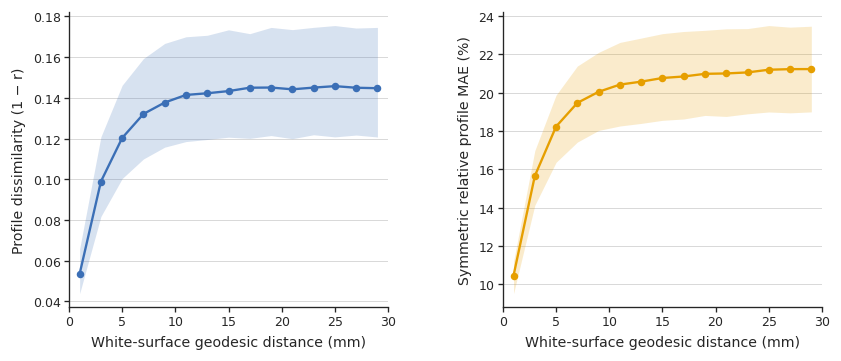

In [3]:
real = pd.read_csv(REAL_DIR / 'figure4_real_group_summary.csv')
real_all = real[real['pair_type'].eq('all')].sort_values('distance_bin_index')
relative_mae = pd.read_csv(
    RELATIVE_MAE_DIR / 'figure4_relative_mae_group_summary.csv'
).sort_values('distance_bin_index')
relative_mae_status = json.loads(
    (RELATIVE_MAE_DIR / 'figure4_relative_mae_status.json').read_text()
)
display(Markdown(
    f"**Symmetric relative MAE.** {relative_mae_status['subjects_completed']}/"
    f"{relative_mae_status['subjects_expected']} subjects completed; "
    f"0–2 mm median = {relative_mae.iloc[0]['median']:.2f}% "
    f"(IQR {relative_mae.iloc[0]['q25']:.2f}–{relative_mae.iloc[0]['q75']:.2f}%); "
    f"28–30 mm = {relative_mae.iloc[-1]['median']:.2f}% "
    f"(IQR {relative_mae.iloc[-1]['q25']:.2f}–{relative_mae.iloc[-1]['q75']:.2f}%)."
))
display(relative_mae[[
    'distance_bin', 'n_subjects', 'median', 'q25', 'q75',
    'bootstrap_ci95_low', 'bootstrap_ci95_high',
    'anchor_count_total', 'pair_count_total',
]])
fig, axes = plt.subplots(
    1, 2, figsize=(FIGURE_WIDTH_IN, 3.15),
    gridspec_kw={'wspace': .36},
)
x = real_all['distance_bin_index'] * 2 + 1
axes[0].plot(x, real_all['median'], marker='o', color=PALETTE['blue'])
axes[0].fill_between(
    x, real_all['q25'], real_all['q75'],
    alpha=.2, color=PALETTE['blue'], linewidth=0,
)
axes[0].set(
    xlabel='White-surface geodesic distance (mm)',
    ylabel='Profile dissimilarity (1 − r)',
    xlim=(0, 30), xticks=np.arange(0, 31, 5),
)
style_axes(axes[0], grid=True)
x_relative = relative_mae['distance_bin_center_mm']
axes[1].plot(
    x_relative, relative_mae['median'], marker='o', color=PALETTE['orange'],
)
axes[1].fill_between(
    x_relative, relative_mae['q25'], relative_mae['q75'],
    alpha=.2, color=PALETTE['orange'], linewidth=0,
)
axes[1].set(
    xlabel='White-surface geodesic distance (mm)',
    ylabel='Symmetric relative profile MAE (%)',
    xlim=(0, 30), xticks=np.arange(0, 31, 5),
)
style_axes(axes[1], grid=True)
fig.subplots_adjust(left=.10, right=.985, bottom=.20, top=.98, wspace=.36)
save_publication_figure(
    fig, FIGURE_DIR / 'figure4_profile_dissimilarity_and_relative_mae_by_distance'
)
plt.show()

### Figure 4A2: Bilateral within-region spatial curves

This regional analysis retains only fixed Figure 4A pairs whose anchor and neighbor have the same DK label. The hierarchy is within-region pair $\rightarrow$ hemisphere × anchor × 2-mm-bin median $\rightarrow$ bilateral subject × DK-region median $\rightarrow$ group median/IQR. Homologous left and right regions are therefore combined inside each subject; pair counts describe support and never weight the metric. Gray cells fail the prespecified coverage rule (at least 20 valid pairs in at least 80% of subjects). The main $1-r$ heatmap is capped at 0.35, with saturated cells marked by the colorbar extension; a compact companion heatmap shows the complete 0–0.90 range for affected regions. Representative curves are selected reproducibly from the 20th, 50th, and 80th percentiles within low, intermediate, and high tertiles of the 0–10-mm regional heterogeneity score, restricted to regions with formal coverage across all 15 bins. All curves show the group median and subject IQR.

**Within-region coverage.** 325/325 subjects; 34 bilateral DK regions; 770,106 fixed directed pairs; 488/510 region × distance cells pass formal coverage. The main $1-r$ scale is capped at 0.35; 66 reliable cells are shown at the upper color limit.

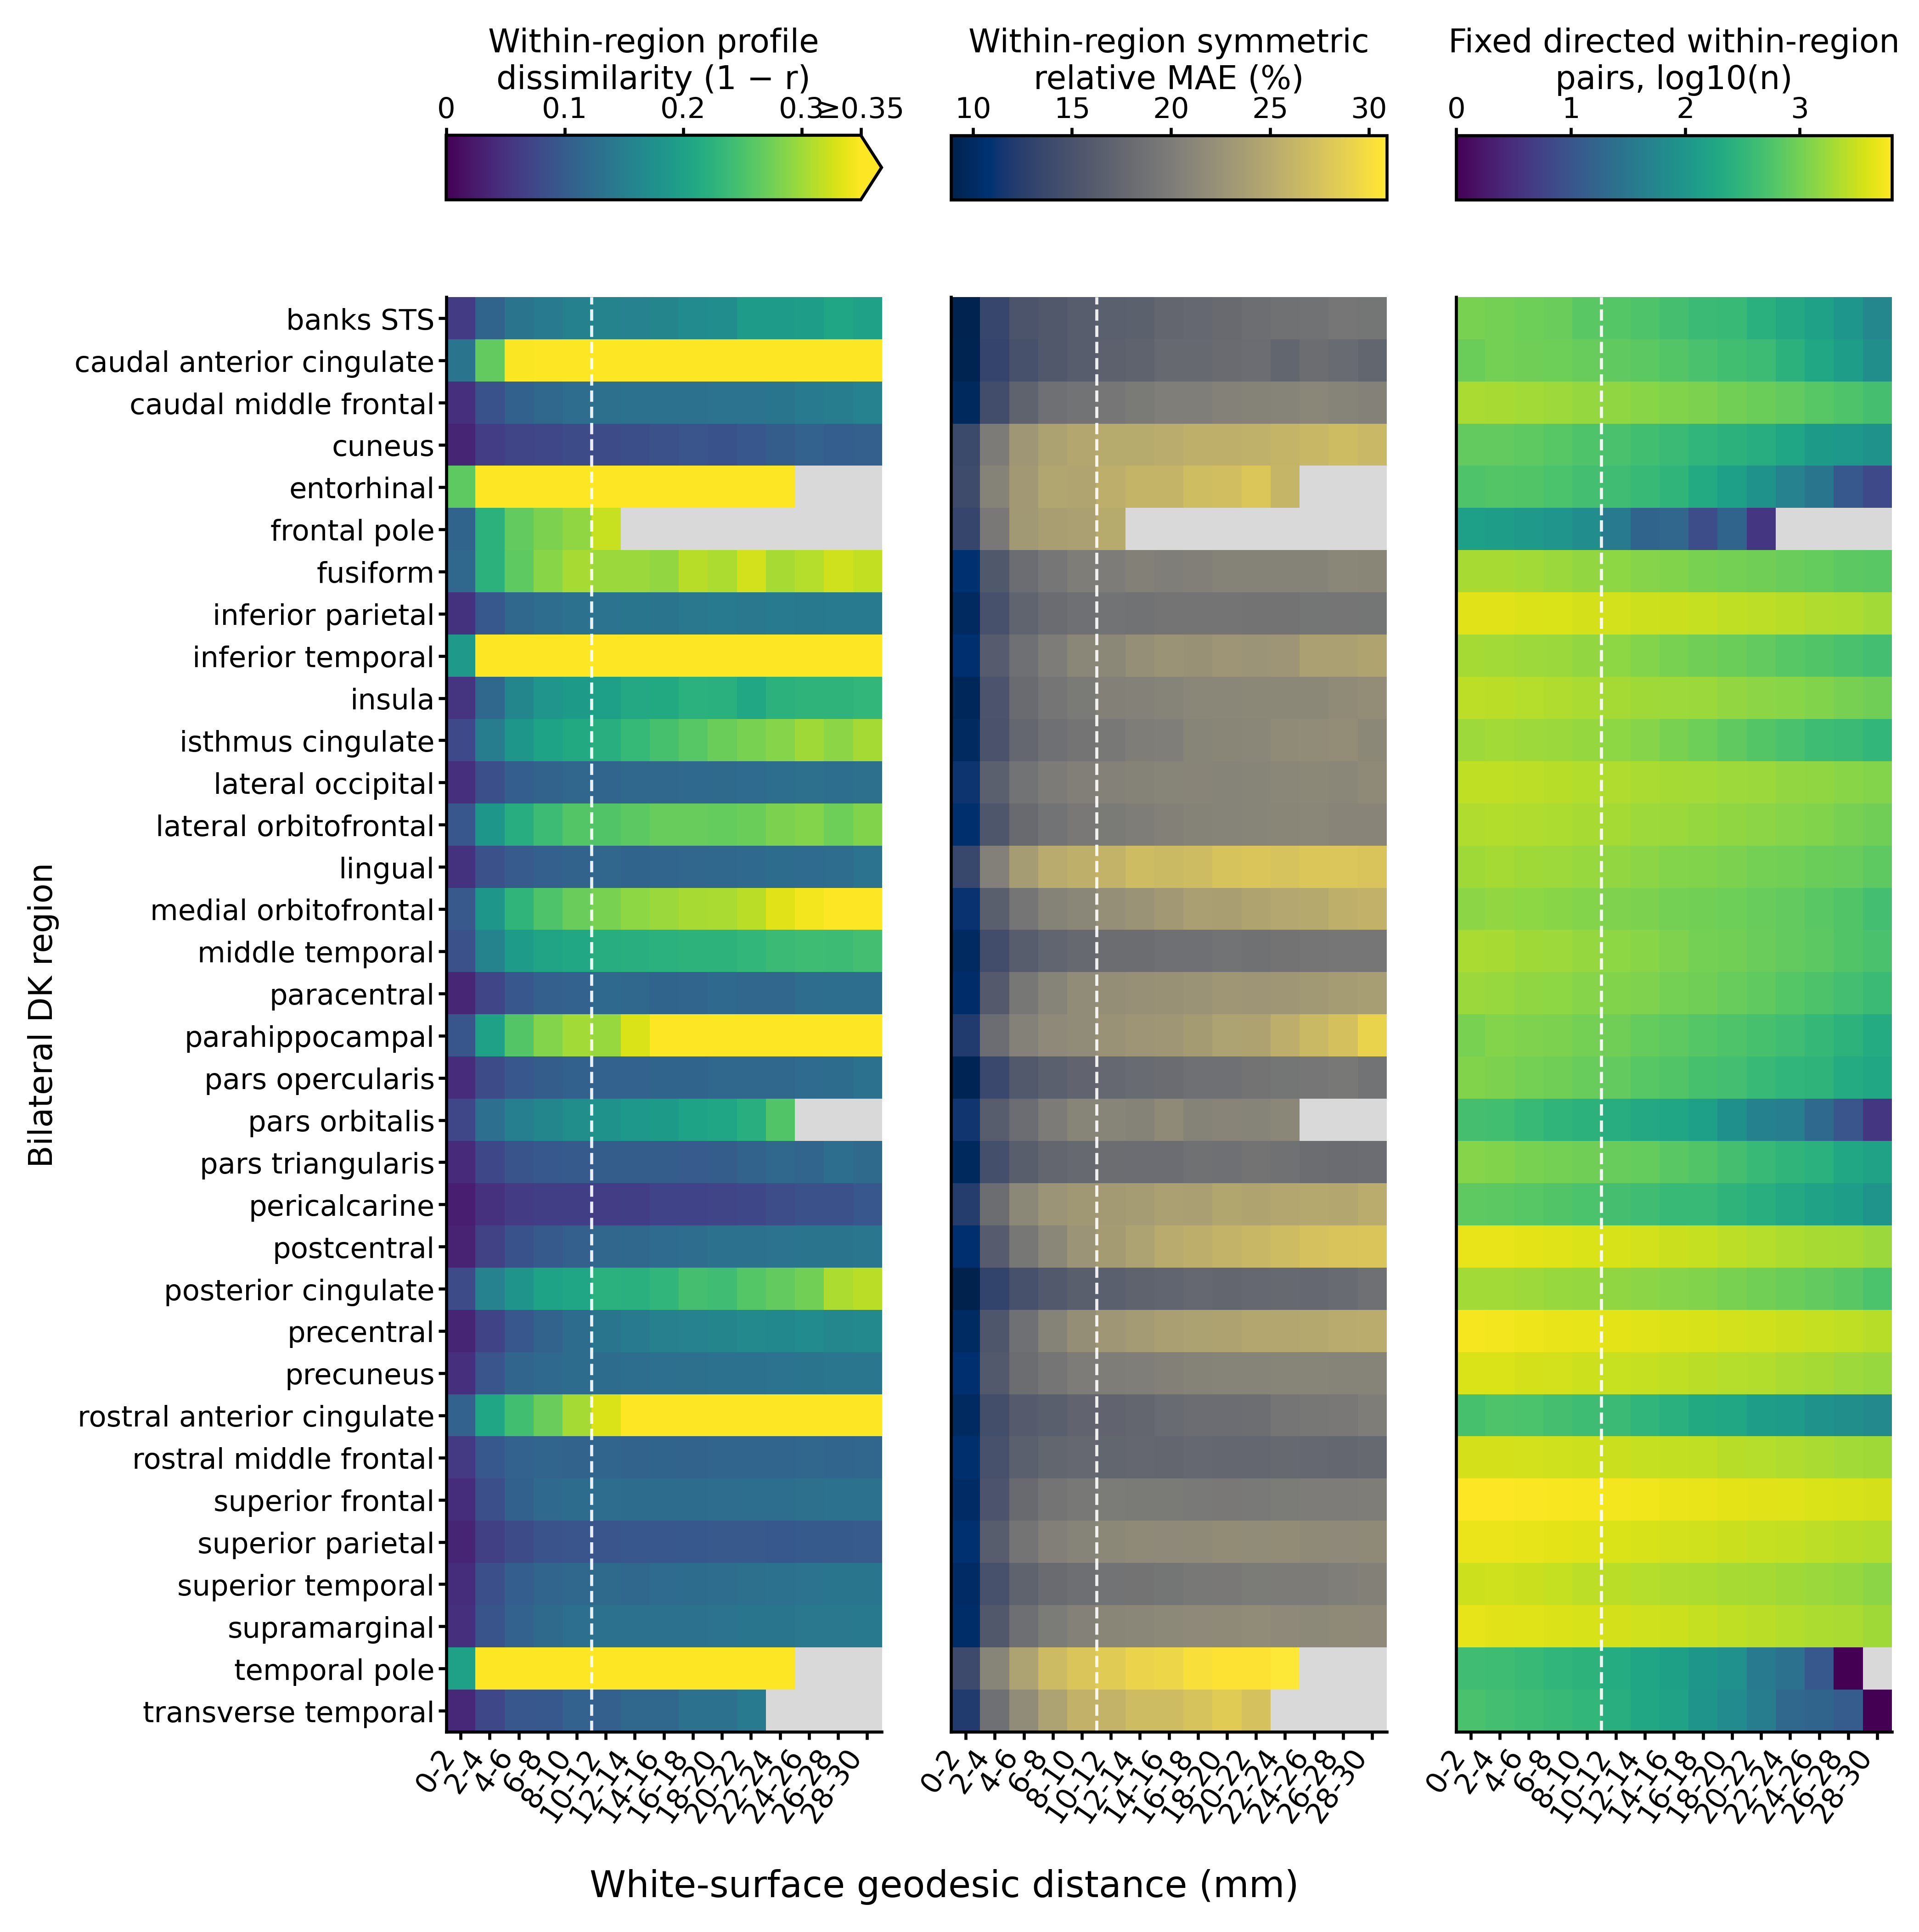

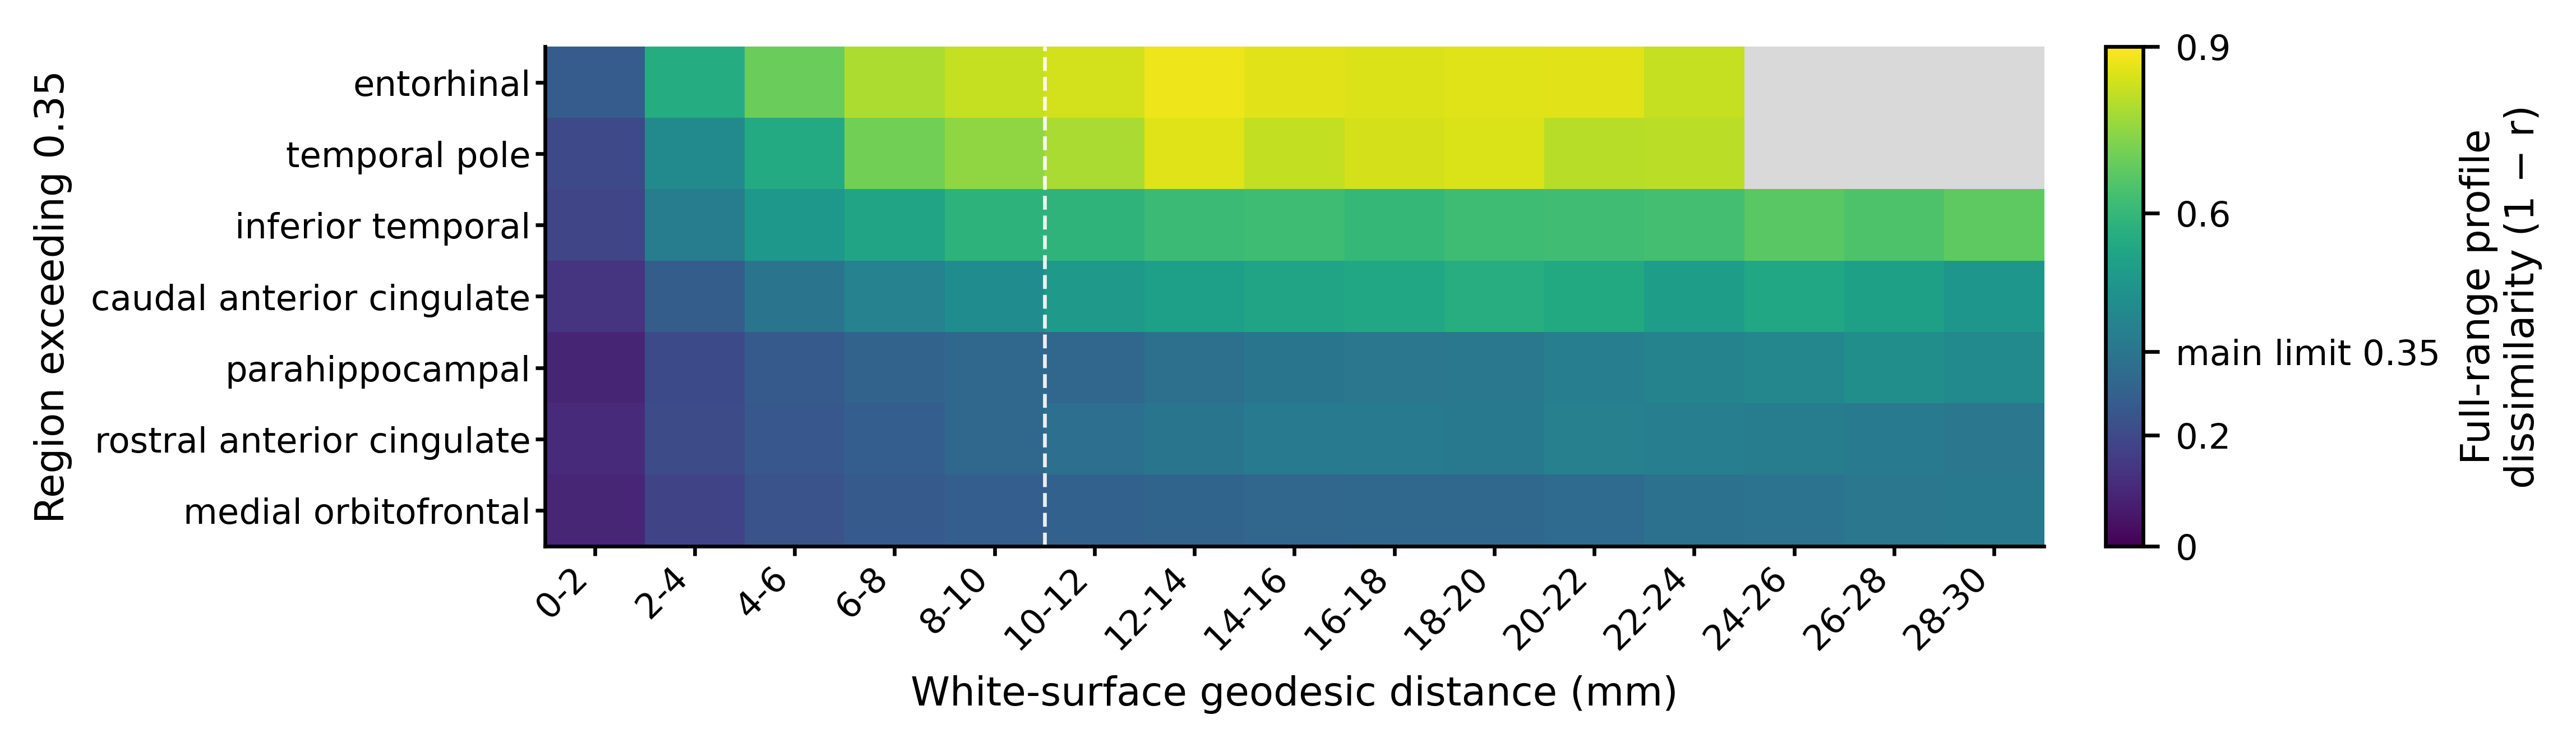

**Representative low, intermediate, and high heterogeneity regions.**

,heterogeneity_class,within_class_quantile_target,dk_region,heterogeneity_0_10
0,Low,0.2,superiorparietal,0.073365
1,Low,0.5,parstriangularis,0.081183
2,Low,0.8,precentral,0.087778
3,Intermediate,0.2,caudalmiddlefrontal,0.097401
4,Intermediate,0.5,precuneus,0.099342
5,Intermediate,0.8,bankssts,0.121313
6,High,0.2,lateralorbitofrontal,0.199003
7,High,0.5,rostralanteriorcingulate,0.226916
8,High,0.8,fusiform,0.239412


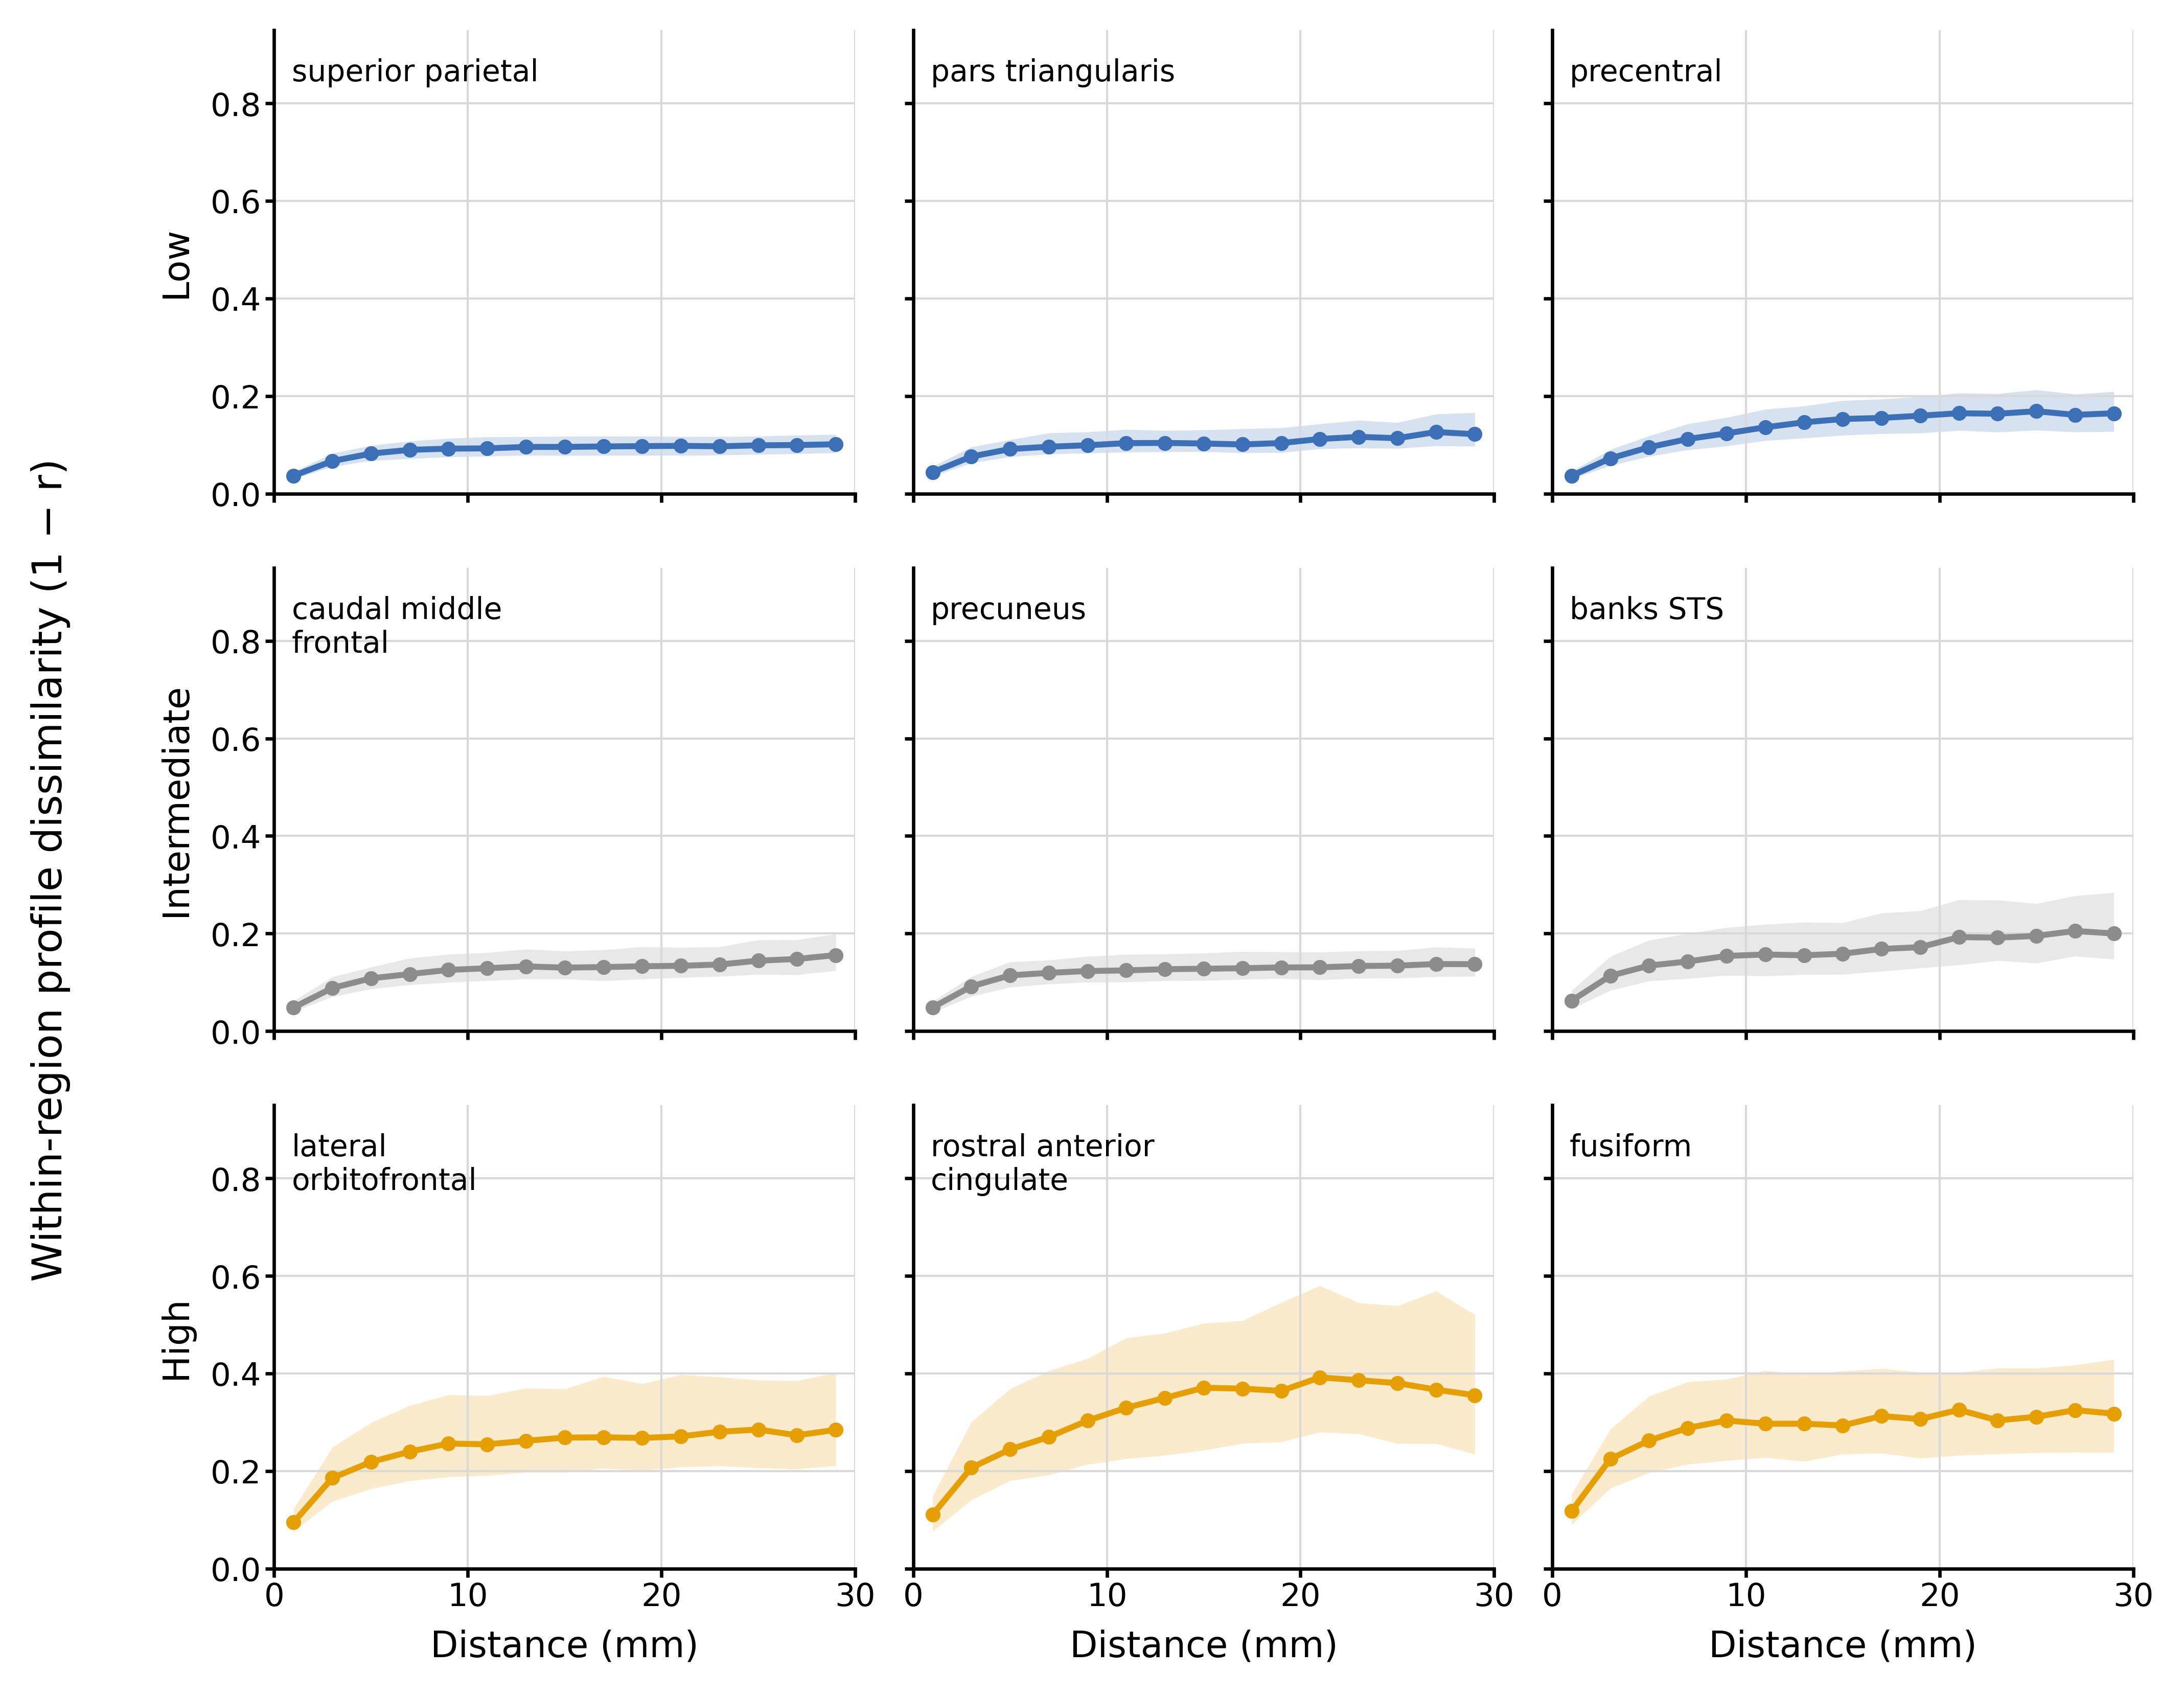

**All bilateral regions as small multiples.**

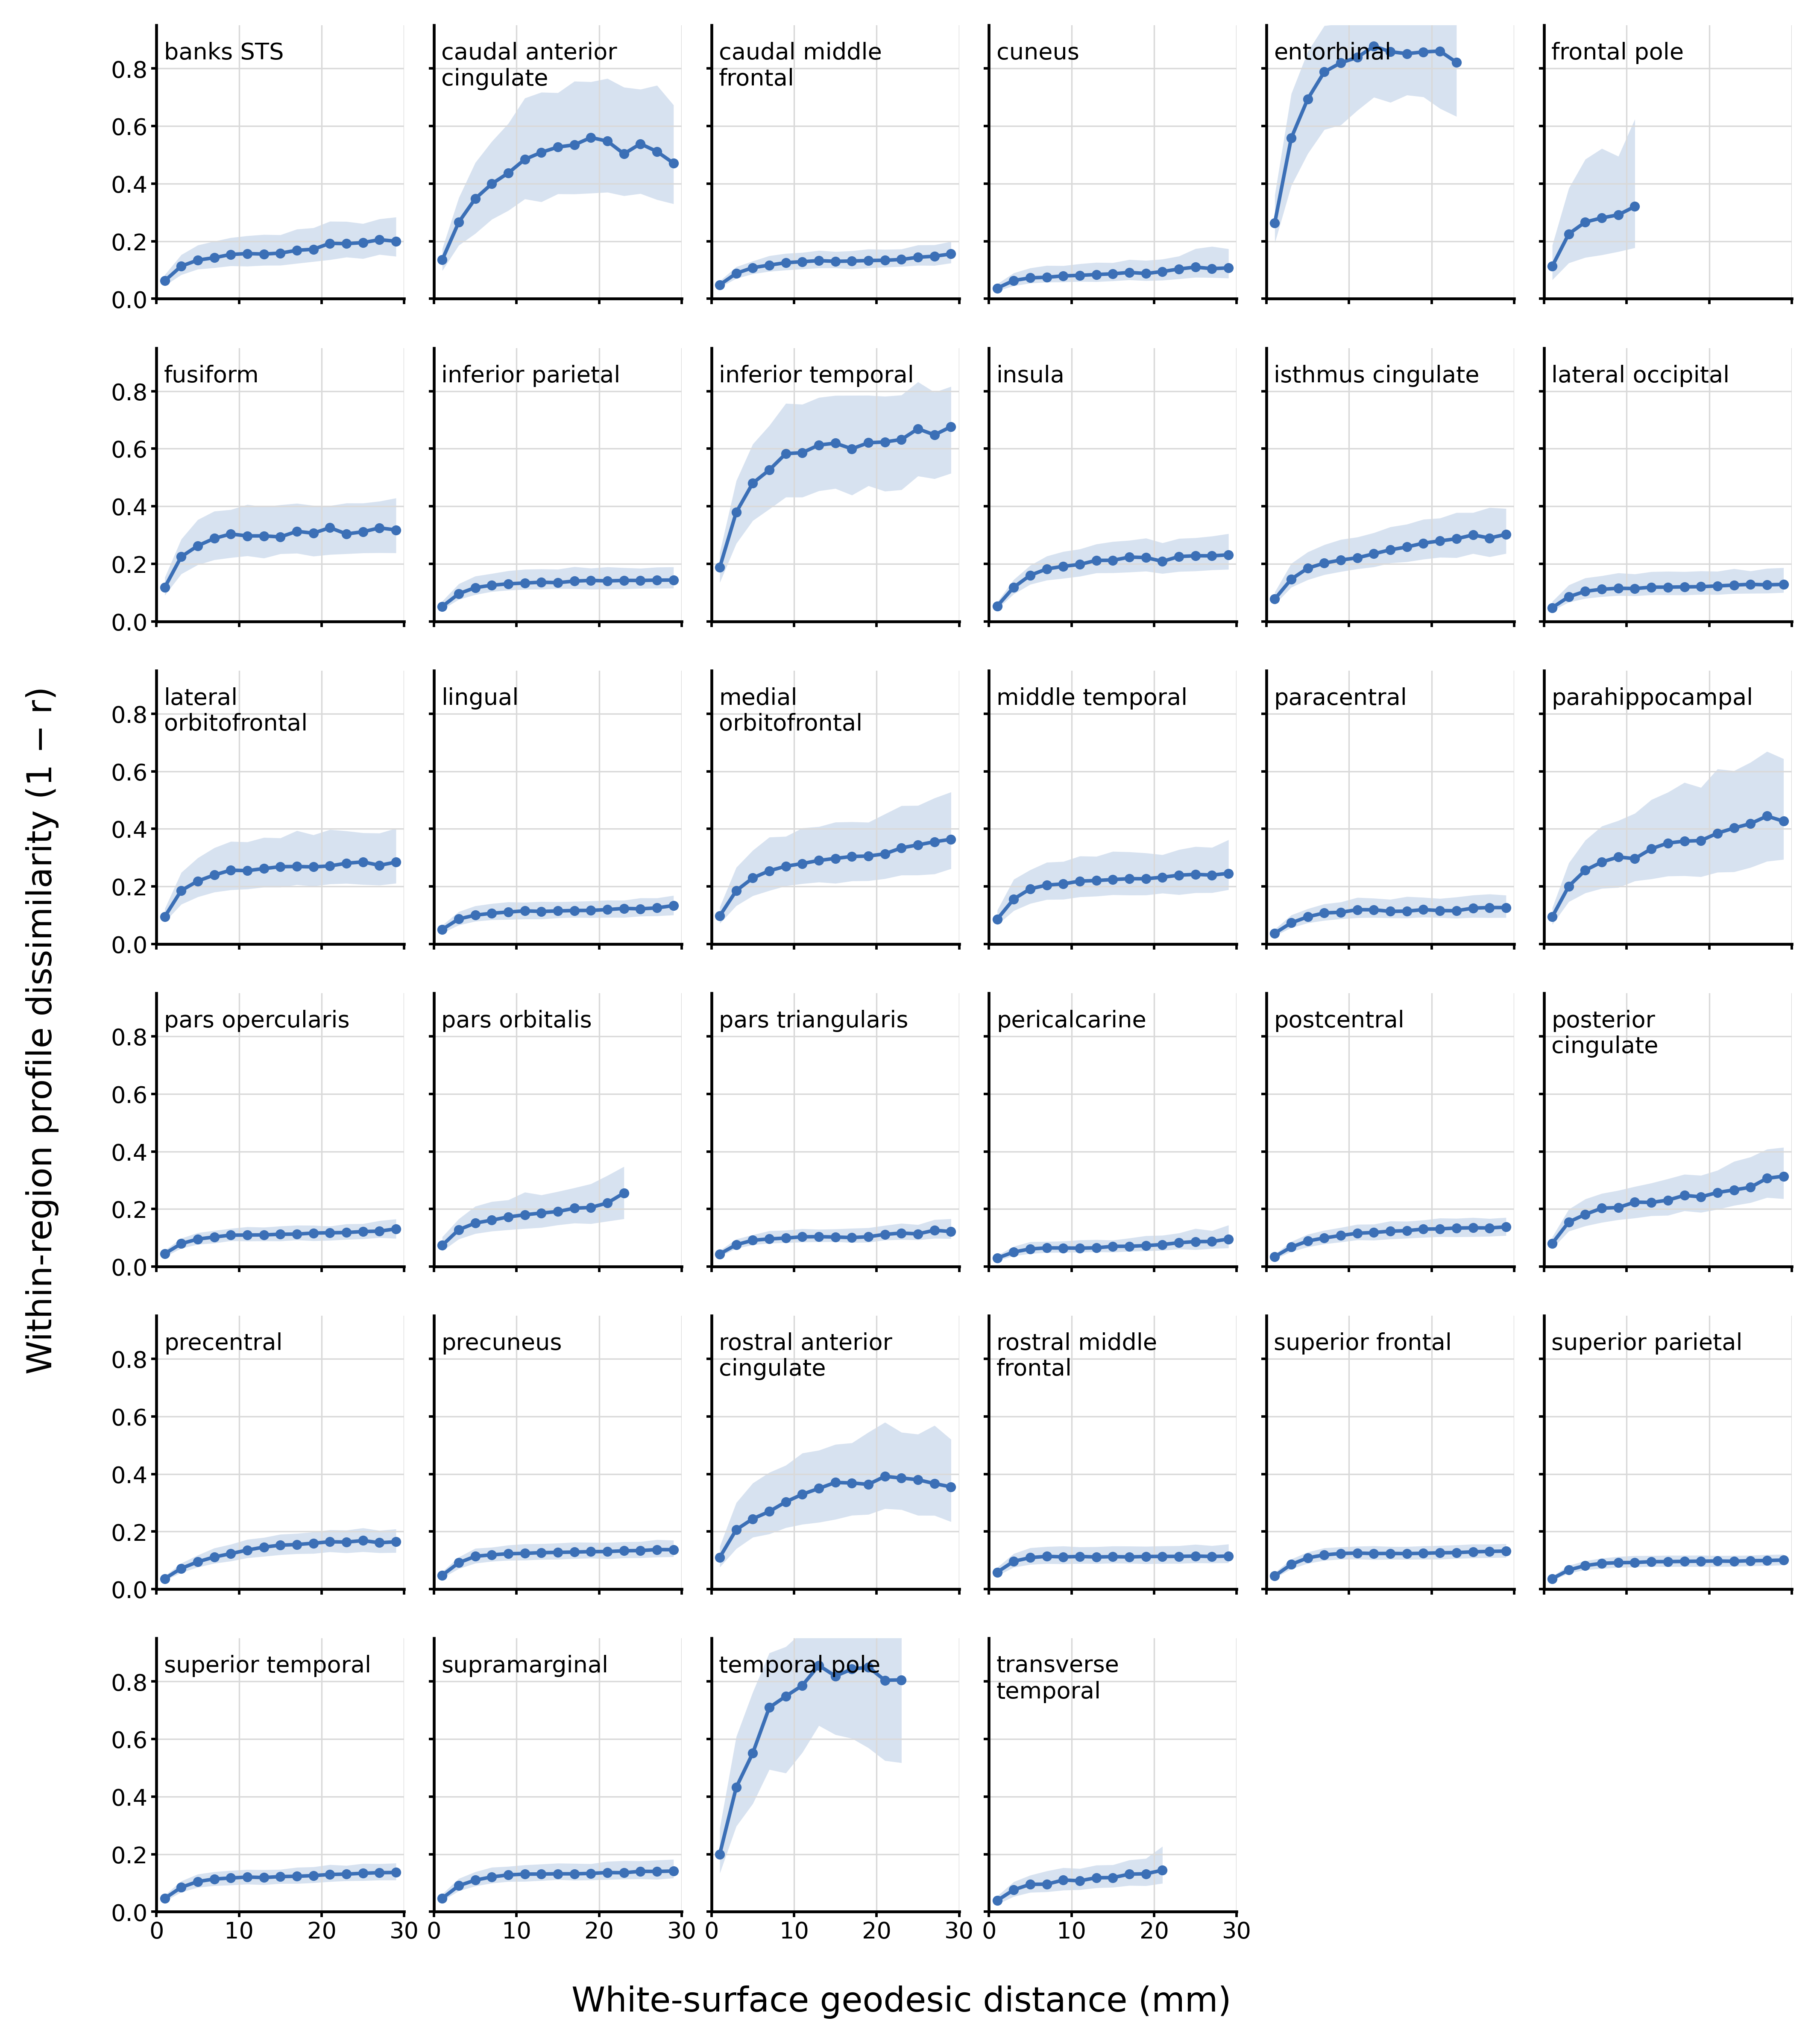

,dk_region,fixed_directed_pairs_0_30,fixed_unique_undirected_pairs_0_30,fixed_directed_pairs_0_10,valid_profile_pairs_0_30_total,valid_profile_pairs_0_30_median_subject,formal_distance_bins,maximum_supported_distance_mm
0,superiorfrontal,74733,74704,30377,24190356,74723.0,15,30
1,precentral,60003,59971,25450,19407494,59989.5,15,30
2,superiorparietal,53971,53952,23111,17449321,53963.0,15,30
3,postcentral,48014,47987,21890,15515539,48007.0,15,30
4,supramarginal,47619,47602,20868,15411433,47618.0,15,30
5,inferiorparietal,47186,47165,20144,15267046,47186.0,15,30
6,rostralmiddlefrontal,41982,41964,17420,13509774,41921.5,15,30
7,precuneus,41535,41514,18035,13449659,41533.0,15,30
8,superiortemporal,35104,35094,15323,11307705,35050.0,15,30
9,lateraloccipital,30069,30055,12873,9082277,29524.5,15,30


In [4]:
within_region_status = json.loads(
    (WITHIN_REGION_DIR / 'figure4A2_status.json').read_text()
)
within_region_inventory = pd.read_csv(
    WITHIN_REGION_DIR / 'figure4A2_within_region_inventory.csv'
).sort_values('fixed_directed_pairs_0_30', ascending=False)
representative_regions = pd.read_csv(
    WITHIN_REGION_DIR / 'figure4A2_representative_regions.csv'
)
display(Markdown(
    f"**Within-region coverage.** {within_region_status['subjects_completed']}/"
    f"{within_region_status['subjects_expected']} subjects; "
    f"{within_region_status['bilateral_regions']} bilateral DK regions; "
    f"{within_region_status['fixed_directed_pairs_total']:,} fixed directed pairs; "
    f"{within_region_status['formal_cells']}/{within_region_status['total_cells']} "
    f"region × distance cells pass formal coverage. The main $1-r$ scale is "
    f"capped at {within_region_status['main_dissimilarity_vmax']:.2f}; "
    f"{within_region_status['cells_clipped_in_main_dissimilarity_heatmap']} "
    f"reliable cells are shown at the upper color limit."
))
display(Image(
    filename=str(FIGURE_DIR / 'Figure4A2_bilateral_within_region_by_distance.png')
))
display(Image(
    filename=str(FIGURE_DIR / 'Figure4A2_high_dissimilarity_full_range.png')
))
display(Markdown('**Representative low, intermediate, and high heterogeneity regions.**'))
display(representative_regions[[
    'heterogeneity_class', 'within_class_quantile_target',
    'dk_region', 'heterogeneity_0_10',
]])
display(Image(
    filename=str(FIGURE_DIR / 'Figure4A2_representative_within_region_curves.png')
))
display(Markdown('**All bilateral regions as small multiples.**'))
display(Image(
    filename=str(FIGURE_DIR / 'Figure4A2_all_within_region_small_multiples.png')
))
display(within_region_inventory[[
    'dk_region', 'fixed_directed_pairs_0_30',
    'fixed_unique_undirected_pairs_0_30', 'fixed_directed_pairs_0_10',
    'valid_profile_pairs_0_30_total',
    'valid_profile_pairs_0_30_median_subject', 'formal_distance_bins',
    'maximum_supported_distance_mm',
]])

### Whole-cortex result restricted to within-region pairs

This complementary whole-cortex curve uses only fixed pairs whose endpoints share the same DK label. The hierarchy is within-region pair $\rightarrow$ hemisphere × anchor × distance-bin median $\rightarrow$ subject median across all bilateral cortical anchors $\rightarrow$ group median/IQR. Regions are not averaged equally: every valid anchor contributes one anchor-level value to its subject summary, while raw pair counts never weight the estimate.

**Within-region whole cortex.** 325/325 subjects; 770,106 fixed pairs. Profile dissimilarity: 0.053 (IQR 0.044–0.066) at 0–2 mm and 0.159 (IQR 0.135–0.193) at 28–30 mm.

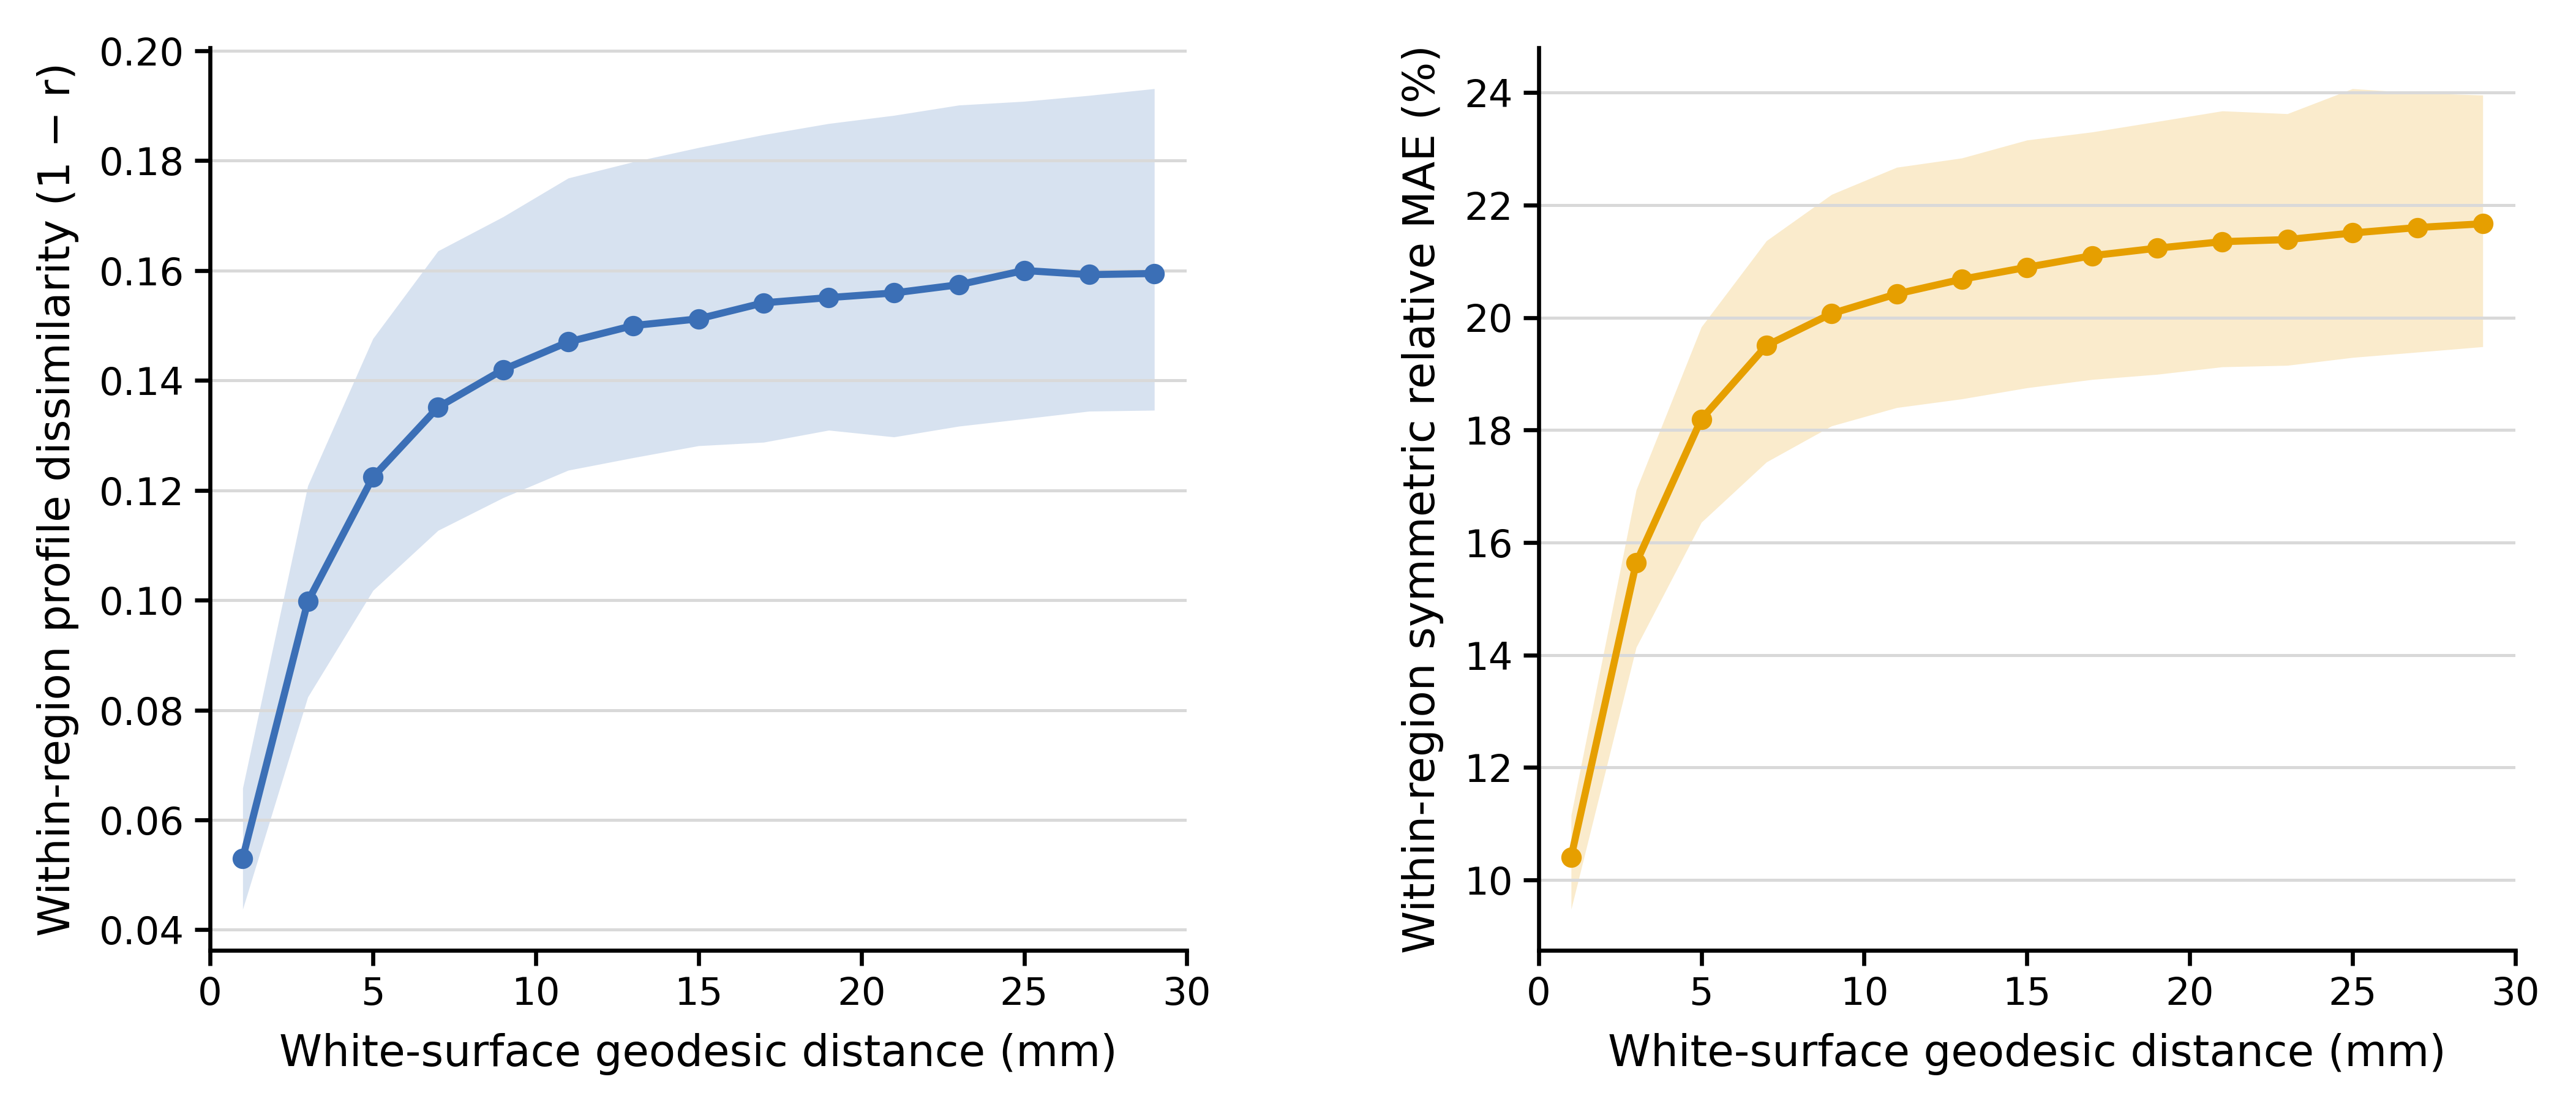

,distance_bin,n_subjects,profile_dissimilarity_median,profile_dissimilarity_q25,profile_dissimilarity_q75,symmetric_relative_mae_pct_median,symmetric_relative_mae_pct_q25,symmetric_relative_mae_pct_q75,fixed_pair_count,valid_pair_count_total,anchor_count_median_subject,region_count_median_subject
0,0-2,325,0.053029,0.043732,0.065785,10.405787,9.477178,11.149868,75399,23905637,4010.0,34.0
1,2-4,325,0.099742,0.082373,0.120835,15.638546,14.136885,16.935833,74736,23516350,4010.0,34.0
2,4-6,325,0.122394,0.101759,0.147622,18.192715,16.358021,19.832777,70627,22182343,4010.0,34.0
3,6-8,325,0.135116,0.112699,0.163577,19.501217,17.430555,21.365448,66691,20919076,4010.0,34.0
4,8-10,325,0.141973,0.118657,0.169801,20.069342,18.071918,22.188419,62365,19553014,4010.0,34.0
5,10-12,325,0.147012,0.123659,0.176844,20.419168,18.397726,22.670414,58438,18319075,4010.0,34.0
6,12-14,325,0.149991,0.125948,0.179800,20.680510,18.552578,22.835703,54532,17101991,4007.0,34.0
7,14-16,325,0.151213,0.128112,0.182390,20.892904,18.749680,23.155098,50459,15820412,4000.0,34.0
8,16-18,325,0.154131,0.128753,0.184736,21.098953,18.897650,23.298349,46717,14657388,3995.0,34.0
9,18-20,325,0.155082,0.130946,0.186768,21.233089,18.989370,23.484720,43126,13535239,3984.0,34.0


In [5]:
within_whole_status = json.loads(
    (WITHIN_WHOLE_CORTEX_DIR / 'figure4_within_region_whole_cortex_status.json').read_text()
)
within_whole = pd.read_csv(
    WITHIN_WHOLE_CORTEX_DIR / 'figure4_within_region_whole_cortex_group_summary.csv'
).sort_values('distance_bin_index')
display(Markdown(
    f"**Within-region whole cortex.** {within_whole_status['subjects_completed']}/"
    f"{within_whole_status['subjects_expected']} subjects; "
    f"{within_whole_status['fixed_within_region_pair_count']:,} fixed pairs. "
    f"Profile dissimilarity: {within_whole.iloc[0]['profile_dissimilarity_median']:.3f} "
    f"(IQR {within_whole.iloc[0]['profile_dissimilarity_q25']:.3f}–"
    f"{within_whole.iloc[0]['profile_dissimilarity_q75']:.3f}) at 0–2 mm and "
    f"{within_whole.iloc[-1]['profile_dissimilarity_median']:.3f} "
    f"(IQR {within_whole.iloc[-1]['profile_dissimilarity_q25']:.3f}–"
    f"{within_whole.iloc[-1]['profile_dissimilarity_q75']:.3f}) at 28–30 mm."
))
display(Image(
    filename=str(FIGURE_DIR / 'Figure4A_within_region_whole_cortex.png')
))
display(within_whole[[
    'distance_bin', 'n_subjects',
    'profile_dissimilarity_median', 'profile_dissimilarity_q25',
    'profile_dissimilarity_q75', 'symmetric_relative_mae_pct_median',
    'symmetric_relative_mae_pct_q25', 'symmetric_relative_mae_pct_q75',
    'fixed_pair_count', 'valid_pair_count_total',
    'anchor_count_median_subject', 'region_count_median_subject',
]])

## 5. Profile MAE versus geodesic distance

Profile MAE is the mean absolute MD difference across the 21 depths for each pair. Pair values have already been median-aggregated within anchor × distance bin and then across anchors and hemispheres within subject. The real curve uses `figure4_real_subject_bins.csv`; the FWHM=0 acquisition null uses `figure4_null_subject_bins.csv` and is additionally median-aggregated across 100 realizations within each subject. Group curves show the across-subject median and IQR at the fixed 1, 3, ..., 29-mm bin centers. The comparison uses only subjects present in both conditions. No MAE local-excess reference is imposed here.

,manifest_subjects,real_subjects,fwhm0_null_subjects,paired_subjects
0,325,325,325,325


,curve,distance_bin_index,distance_bin_center_mm,n_subjects,median,q25,q75
0,Real,0,1,325,0.000077,0.000070,0.000084
1,Real,1,3,325,0.000114,0.000103,0.000125
2,Real,2,5,325,0.000132,0.000118,0.000147
3,Real,3,7,325,0.000141,0.000126,0.000157
4,Real,4,9,325,0.000145,0.000130,0.000162
5,Real,5,11,325,0.000147,0.000132,0.000166
6,Real,6,13,325,0.000149,0.000133,0.000167
7,Real,7,15,325,0.000150,0.000134,0.000170
8,Real,8,17,325,0.000151,0.000135,0.000170
9,Real,9,19,325,0.000151,0.000136,0.000170


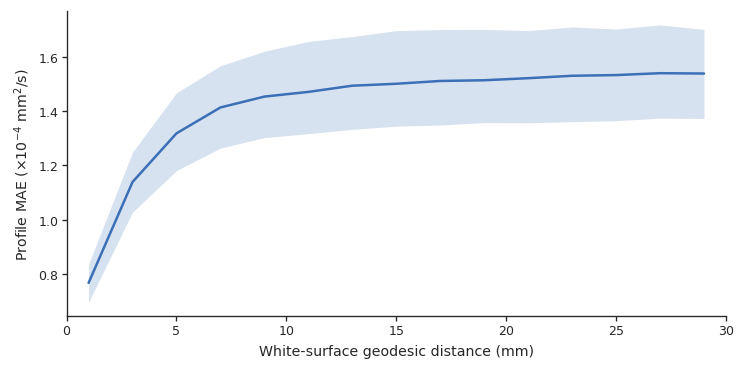

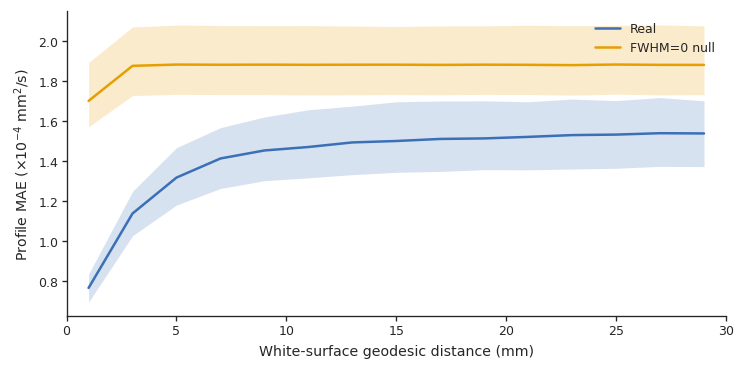

In [6]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path(
    '/mnt/newStor/paros/paros_WORK/xintong/results/qc/'
    'full_cohort_spatial_scale'
)
REPO_ROOT = Path(
    '/mnt/newStor/paros/paros_WORK/xintong/code/'
    'cortical_trajectory_analysis'
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from qc.publication_style import (
    FIGURE_WIDTH_IN, PALETTE, save_publication_figure,
    set_publication_style, style_axes,
)
set_publication_style()
FIGURE_DIR = ROOT / 'figures'

MAE_REAL_ROOT = ROOT / 'figure4_real'
MAE_FWHM0_NULL_ROOT = ROOT / 'figure4_acquisition_sampling_full325_fwhm0'
MAE_MANIFEST = REPO_ROOT / 'manifests/figure4_valid_325_subjects.csv'
MAE_BIN_INDICES = np.arange(15)
MAE_BIN_CENTERS_MM = 2 * MAE_BIN_INDICES + 1
MAE_DISPLAY_SCALE = 1e4


def load_mae_subject_tables(results_root, filename, subject_ids):
    tables = []
    for subject_id in subject_ids:
        path = results_root / 'subjects' / subject_id / filename
        if path.is_file():
            tables.append(pd.read_csv(path).assign(subject_id=subject_id))
    if not tables:
        raise RuntimeError(f'No {filename} files found under {results_root}')
    return pd.concat(tables, ignore_index=True)


def summarize_mae_subjects(table, is_null=False):
    table = table.loc[
        table['pair_type'].eq('all'),
        ['subject_id', 'distance_bin_index', 'median_profile_mae']
        + (['replicate', 'psf_fwhm_mm'] if is_null else []),
    ].copy()
    table = table.loc[table['distance_bin_index'].isin(MAE_BIN_INDICES)]
    if is_null:
        table = table.loc[np.isclose(table['psf_fwhm_mm'], 0)]
        table = (
            table.groupby(['subject_id', 'distance_bin_index'], observed=True)
            ['median_profile_mae'].median().reset_index()
        )
    counts = table.groupby('subject_id')['distance_bin_index'].nunique()
    if not counts.eq(15).all():
        raise ValueError('Every included subject must contribute all 15 MAE bins')
    return table


def summarize_mae_group(table, label):
    summary = (
        table.groupby('distance_bin_index', observed=True)['median_profile_mae']
        .agg(
            n_subjects='count', median='median',
            q25=lambda values: values.quantile(.25),
            q75=lambda values: values.quantile(.75),
        )
        .reindex(MAE_BIN_INDICES).reset_index()
    )
    summary.insert(0, 'curve', label)
    summary.insert(2, 'distance_bin_center_mm', MAE_BIN_CENTERS_MM)
    return summary


def draw_mae_curve(ax, summary, color, label):
    x = summary['distance_bin_center_mm'].to_numpy(dtype=float)
    median = summary['median'].to_numpy(dtype=float) * MAE_DISPLAY_SCALE
    q25 = summary['q25'].to_numpy(dtype=float) * MAE_DISPLAY_SCALE
    q75 = summary['q75'].to_numpy(dtype=float) * MAE_DISPLAY_SCALE
    ax.plot(x, median, color=color, linewidth=1.5, label=label)
    ax.fill_between(x, q25, q75, color=color, alpha=.2, linewidth=0)


mae_subject_ids = (
    pd.read_csv(MAE_MANIFEST, dtype={'subject_id': str})['subject_id']
    .drop_duplicates().tolist()
)
mae_real = summarize_mae_subjects(load_mae_subject_tables(
    MAE_REAL_ROOT, 'figure4_real_subject_bins.csv', mae_subject_ids,
))
mae_null = summarize_mae_subjects(load_mae_subject_tables(
    MAE_FWHM0_NULL_ROOT, 'figure4_null_subject_bins.csv', mae_subject_ids,
), is_null=True)
mae_paired_subjects = sorted(
    set(mae_real['subject_id']) & set(mae_null['subject_id'])
)
mae_real_group = summarize_mae_group(mae_real, 'Real')
mae_comparison_group = pd.concat([
    summarize_mae_group(
        mae_real.loc[mae_real['subject_id'].isin(mae_paired_subjects)], 'Real',
    ),
    summarize_mae_group(
        mae_null.loc[mae_null['subject_id'].isin(mae_paired_subjects)],
        'FWHM=0 null',
    ),
])
display(pd.DataFrame([{
    'manifest_subjects': len(mae_subject_ids),
    'real_subjects': mae_real['subject_id'].nunique(),
    'fwhm0_null_subjects': mae_null['subject_id'].nunique(),
    'paired_subjects': len(mae_paired_subjects),
}]))
display(mae_comparison_group)

mae_ylabel = r'Profile MAE ($\times 10^{-4}$ mm$^2$/s)'
mae_xlabel = 'White-surface geodesic distance (mm)'
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.3))
draw_mae_curve(ax, mae_real_group, PALETTE['blue'], 'Real')
ax.set(xlabel=mae_xlabel, ylabel=mae_ylabel,
       xticks=np.arange(0, 31, 5), xlim=(0, 30))
style_axes(ax)
save_publication_figure(fig, FIGURE_DIR / 'Figure4_real_profile_mae_0_30mm')
plt.show()

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.3))
for label, color in (('Real', PALETTE['blue']),
                     ('FWHM=0 null', PALETTE['orange'])):
    draw_mae_curve(
        ax, mae_comparison_group.loc[mae_comparison_group['curve'].eq(label)],
        color, label,
    )
ax.set(xlabel=mae_xlabel, ylabel=mae_ylabel,
       xticks=np.arange(0, 31, 5), xlim=(0, 30))
ax.legend(frameon=True, facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
style_axes(ax)
save_publication_figure(fig, FIGURE_DIR / 'Figure4_real_vs_fwhm0_profile_mae')
plt.show()

## 6. Figure 4B: Acquisition-and-sampling null

The primary acquisition-and-sampling null generates independent Gaussian fields on each subject's native DWI grid, applies **0-mm additional Gaussian FWHM**, samples the fields at the real transformed O3 coordinates with trilinear interpolation and the exact real-data mask, and then matches the subject-specific 21-depth mean and covariance. It estimates local similarity attributable to voxel sharing and interpolation without adding an assumed extra blur.

The two main Figure 4B displays are rendered separately at the full 180-mm width to preserve legibility. The first directly compares the real and technical-null profile-dissimilarity curves; solid lines denote subject-level group medians and shading denotes IQR. The second removes the separate far-distance offsets by defining

$$
L(d)=D_{20\text{–}30\,\mathrm{mm}}-D(d)
$$

and plotting

$$
\Delta L(d)=L_{\mathrm{real}}(d)-L_{\mathrm{null}}(d).
$$

Thus the residual panel quantifies how much additional local similarity remains in the real data relative to each curve's own 20–30-mm reference. The gray band marks the prespecified 0–10-mm residual window. The DWI-grid result contains all 325 valid subjects × 100 realizations.

The subject-level scalar summary,

$$
\mathrm{AUC}_{0-10}=\int_0^{10}\Delta L(d)\,\mathrm{d}d,
$$

is shown separately in Supplement, with one point per subject plus the group median and IQR. The whole-profile spatial-permutation sensitivity analysis is also plotted separately. It uses the prespecified 20-subject subset × 20 permutations and preserves intact observed 21-depth profiles while removing their surface locations.

In [ ]:
def plot_null_result(group, auc_subject, null_label, null_color, output_stem):
    """Save raw and residual main displays separately; put AUC in Supplement."""
    group = group.sort_values('distance_bin_index')
    x = group['distance_bin_index'].to_numpy(dtype=float) * 2 + 1

    # Main Figure 4B, display 1: raw real-versus-null curves.
    absolute_fig, absolute_ax = plt.subplots(
        figsize=(FIGURE_WIDTH_IN, 3.0)
    )
    absolute_ax.axvspan(
        0, 10, color=PALETTE['masked'], alpha=.35,
        linewidth=0, zorder=0,
    )
    absolute_ax.text(
        5, .975, '0–10 mm residual window',
        transform=absolute_ax.get_xaxis_transform(), ha='center', va='top',
        fontsize=7, color=PALETTE['reference'],
    )
    absolute_ax.plot(
        x, group['real_dissimilarity_median'], color=PALETTE['blue'],
        linewidth=1.5, label='Real', zorder=3,
    )
    absolute_ax.fill_between(
        x, group['real_dissimilarity_q25'], group['real_dissimilarity_q75'],
        color=PALETTE['blue'], alpha=.2, linewidth=0, zorder=1,
    )
    absolute_ax.plot(
        x, group['null_dissimilarity_median'], color=null_color,
        linewidth=1.4, linestyle='--', label=null_label, zorder=3,
    )
    absolute_ax.fill_between(
        x, group['null_dissimilarity_q25'], group['null_dissimilarity_q75'],
        color=null_color, alpha=.16, linewidth=0, zorder=1,
    )
    absolute_ax.set(
        xlabel='White-surface geodesic distance (mm)',
        ylabel='Profile dissimilarity (1 − r)',
        xlim=(0, 30),
    )
    absolute_ax.legend(frameon=True, loc='lower right', facecolor="white", edgecolor="#D0D0D0", framealpha=.90, fancybox=False, fontsize=7.5, borderpad=.35, labelspacing=.35, handlelength=1.8, handletextpad=.5)
    style_axes(absolute_ax)
    absolute_fig.subplots_adjust(left=.12, right=.985, bottom=.20, top=.97)
    save_publication_figure(absolute_fig, FIGURE_DIR / output_stem)
    plt.show()

    # Main Figure 4B, display 2: distance-resolved platform-adjusted residual.
    residual_fig, residual_ax = plt.subplots(
        figsize=(FIGURE_WIDTH_IN, 3.0)
    )
    residual_ax.axvspan(
        0, 10, color=PALETTE['masked'], alpha=.35,
        linewidth=0, zorder=0,
    )
    residual_ax.plot(
        x, group['real_minus_null_local_excess_median'],
        color=null_color, linewidth=1.4, zorder=3,
    )
    residual_ax.fill_between(
        x, group['real_minus_null_local_excess_q25'],
        group['real_minus_null_local_excess_q75'],
        color=null_color, alpha=.2, linewidth=0, zorder=1,
    )
    residual_ax.axhline(
        0, color=PALETTE['reference'], linewidth=.8, linestyle='--',
    )
    residual_ax.set(
        xlabel='White-surface geodesic distance (mm)',
        ylabel=(
            'Residual local-excess similarity\n'
            r'$L_{\mathrm{real}}(d)-L_{\mathrm{null}}(d)$'
        ),
        xlim=(0, 30),
    )
    style_axes(residual_ax)
    residual_fig.subplots_adjust(left=.13, right=.985, bottom=.20, top=.97)
    save_publication_figure(
        residual_fig, FIGURE_DIR / f'{output_stem}_residual_curve'
    )
    plt.show()

    # Supplement: one point per subject, with group median and IQR.
    values = auc_subject['auc_residual_local_excess_0_10_mm'].to_numpy(dtype=float)
    jitter = np.random.default_rng(20261021).uniform(-.13, .13, len(values))
    q25, median, q75 = np.quantile(values, [.25, .5, .75])
    positive_fraction = np.mean(values > 0)

    auc_fig, auc_ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 2.35))
    auc_ax.scatter(
        values, jitter, s=9, color=null_color, alpha=.60,
        linewidth=0, rasterized=True,
    )
    auc_ax.axvline(
        0, color=PALETTE['reference'], linewidth=.8, linestyle='--',
    )
    auc_ax.hlines(
        0, q25, q75, color=PALETTE['reference'], linewidth=2.4,
    )
    auc_ax.vlines(
        median, -.18, .18, color=PALETTE['reference'], linewidth=1.2,
    )
    auc_ax.text(
        .985, .95,
        f'median = {median:.3f} Δr·mm\n'
        f'IQR = {q25:.3f}–{q75:.3f}; positive = {positive_fraction:.1%}',
        transform=auc_ax.transAxes, ha='right', va='top', fontsize=7,
    )
    auc_ax.set(
        xlabel='Residual local-excess AUC, 0–10 mm (Δr × mm)',
        yticks=[], ylim=(-.23, .23),
    )
    style_axes(auc_ax)
    auc_ax.spines['left'].set_visible(False)
    auc_fig.subplots_adjust(left=.10, right=.985, bottom=.25, top=.96)
    save_publication_figure(
        auc_fig, FIGURE_DIR / f'{output_stem}_auc_supplement'
    )
    plt.show()


# Primary technical null: native DWI grid with no additional Gaussian blur.
acquisition_validation = json.loads(
    (ACQUISITION_NULL_DIR / 'figure4B_acquisition_validation_summary.json').read_text()
)
acquisition_group_all = pd.read_csv(
    ACQUISITION_NULL_DIR / 'figure4B_acquisition_group_summary.csv'
)
acquisition_auc_subject_all = pd.read_csv(
    ACQUISITION_NULL_DIR / 'figure4B_local_excess_auc_subject.csv'
)
n_acquisition_realizations = int(acquisition_group_all['n_realizations'].max())
acquisition_fwhm0 = acquisition_group_all[
    acquisition_group_all['n_realizations'].eq(n_acquisition_realizations)
    & acquisition_group_all['psf_fwhm_mm'].eq(0)
].copy()
acquisition_fwhm0_auc = acquisition_auc_subject_all[
    acquisition_auc_subject_all['psf_fwhm_mm'].eq(0)
].copy()
acquisition_auc_values = acquisition_fwhm0_auc[
    'auc_residual_local_excess_0_10_mm'
].to_numpy(dtype=float)
acquisition_auc_q25, acquisition_auc_median, acquisition_auc_q75 = np.quantile(
    acquisition_auc_values, [.25, .5, .75]
)
acquisition_auc_positive = np.mean(acquisition_auc_values > 0)
acquisition_subject_summary = pd.read_csv(
    ACQUISITION_NULL_DIR / 'figure4B_acquisition_subject_summary.csv'
)
acquisition_near = acquisition_subject_summary[
    acquisition_subject_summary['n_realizations'].eq(n_acquisition_realizations)
    & acquisition_subject_summary['psf_fwhm_mm'].eq(0)
    & acquisition_subject_summary['distance_bin_index'].eq(0)
].copy()
acquisition_near_fraction = np.median(
    acquisition_near['null_local_excess_similarity']
    / acquisition_near['real_local_excess_similarity']
)
display(Markdown(
    f"**DWI-grid Gaussian FWHM 0 mm.** "
    f"{acquisition_validation['subjects_expected']} subjects × "
    f"{n_acquisition_realizations} realizations. At 0–2 mm, the technical "
    f"null accounts for a median {100 * acquisition_near_fraction:.1f}% of "
    f"real local-excess similarity. The 0–10-mm residual AUC is "
    f"{acquisition_auc_median:.3f} Δr·mm "
    f"(IQR {acquisition_auc_q25:.3f}–{acquisition_auc_q75:.3f}); "
    f"{100 * acquisition_auc_positive:.1f}% of subjects have positive AUC."
))
plot_null_result(
    acquisition_fwhm0,
    acquisition_fwhm0_auc,
    'DWI grid\nFWHM 0 mm',
    PALETTE['orange'],
    'Figure4B_acquisition_fwhm0_main',
)


# Sensitivity null: intact observed profiles shuffled among surface vertices.
whole_report = json.loads(
    (WHOLE_PROFILE_NULL_DIR / 'figure4B_null_comparison_report.json').read_text()
)
whole_group_all = pd.read_csv(
    WHOLE_PROFILE_NULL_DIR / 'figure4B_null_comparison_group_summary.csv'
)
whole_group = whole_group_all[
    whole_group_all['method'].eq('Whole-profile permutation')
].copy()
whole_auc_all = pd.read_csv(
    WHOLE_PROFILE_NULL_DIR / 'figure4B_null_comparison_auc_subject.csv'
)
whole_auc = whole_auc_all[
    whole_auc_all['method'].eq('Whole-profile permutation')
].copy()
whole_auc_median = whole_auc['auc_residual_local_excess_0_10_mm'].median()
display(Markdown(
    f"**Whole-profile spatial permutation.** "
    f"{whole_report['number_of_subjects']} subjects × "
    f"{whole_report['whole_profile_realizations']} permutations; all mappings "
    f"bijective, count mismatch rows = {whole_report['count_mismatch_rows']}; "
    f"median 0–10-mm residual AUC = {whole_auc_median:.3f} Δr·mm. "
    f"At 0–2 mm, the DWI-grid null accounts for a median "
    f"{100 * whole_report['median_0_2_mm_acquisition_fraction_of_real_local_excess']:.1f}% "
    f"of real local excess similarity in the paired 20-subject pilot."
))
plot_null_result(
    whole_group,
    whole_auc,
    'Whole-profile\npermutation',
    '#90BEE0',
    'Figure4B_whole_profile_permutation_pilot20',
)


## 7. Figure 4C: Correlation length and split-half reliability

,n_subjects,pearson_r,spearman_rho,icc_two_way_single,median_absolute_difference_mm,n_failed_fits
0,325,0.67087,0.549599,0.670064,0.187699,0


,fit_scope,n_fits,n_acceptable,n_boundary,median_r2
0,fixed_half_1,325,324,0,0.990481
1,fixed_half_2,325,324,1,0.989961


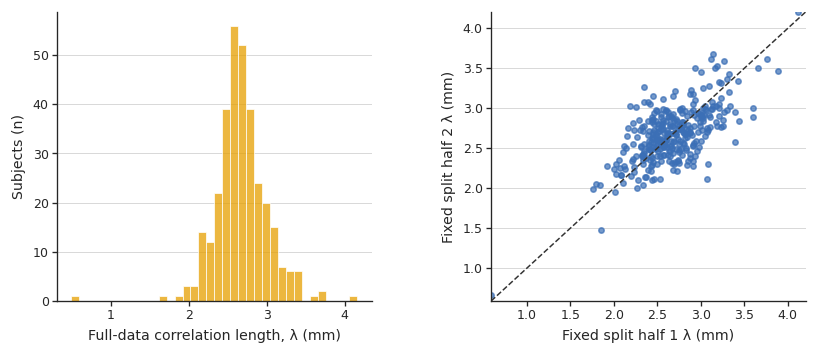

In [8]:
lengths = pd.read_csv(REAL_DIR / "figure4_correlation_lengths.csv")
fixed_fits = pd.read_csv(REAL_DIR / 'figure4_fixed_split_half_fits.csv')
reliability = pd.read_csv(REAL_DIR / 'figure4_fixed_split_half_reliability.csv')
display(reliability)
display(fixed_fits.groupby('fit_scope', as_index=False).agg(
    n_fits=('subject_id', 'size'),
    n_acceptable=('fit_acceptable', 'sum'),
    n_boundary=('hit_parameter_boundary', 'sum'),
    median_r2=('fit_r2', 'median'),
))
halves = fixed_fits.pivot(index='subject_id', columns='fit_scope', values='lambda_mm').dropna()
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH_IN, 3.05), gridspec_kw={'wspace': 0.38})
sns.histplot(data=lengths[lengths['fit_scope'].eq('full')], x='lambda_mm', ax=axes[0], color=PALETTE['orange'])
axes[0].set(xlabel='Full-data correlation length, λ (mm)', ylabel='Subjects (n)')
style_axes(axes[0], grid=True)
axes[1].scatter(halves['fixed_half_1'], halves['fixed_half_2'], s=10, color=PALETTE['blue'], alpha=0.7)
limits = [halves.to_numpy().min(), halves.to_numpy().max()]
axes[1].plot(limits, limits, color=PALETTE['reference'], linewidth=0.9, linestyle='--')
axes[1].set(xlabel='Fixed split half 1 λ (mm)', ylabel='Fixed split half 2 λ (mm)', xlim=limits, ylim=limits)
style_axes(axes[1], grid=True)
fig.subplots_adjust(left=0.10, right=0.98, bottom=0.18, top=0.97, wspace=0.38)
save_publication_figure(fig, FIGURE_DIR / 'figure4_correlation_length_and_fixed_split_half')
plt.show()

## 8. Figure 4D: DK-region effect using all fixed pairs

The primary analysis classifies every fixed Figure 4A pair as same-region or different-region from its endpoint DK labels. To avoid pair-count weighting and residual distance imbalance, aggregation proceeds as

```
pair dissimilarity
→ anchor × 0.5-mm distance-sub-bin median
→ hemisphere × anchor-DK-region × sub-bin median
→ subject median
→ group median and IQR
```

Within- and across-region values are compared only within the same hemisphere, anchor DK region, and 0.5-mm sub-bin, but they do not need to originate from the same anchor. The subject-level effect is

$$
\Delta D_s(d)=\operatorname{median}_{\mathrm{region,subbin}}
\left[D_{\mathrm{different}}-D_{\mathrm{same}}\right].
$$

Positive values indicate that profiles assigned to different DK regions are more dissimilar than profiles assigned to the same DK region at matched geodesic distance.

A complementary MAE analysis uses the identical hierarchy and matching. It tests absolute profile-value differences, whereas $1-r$ tests profile-shape dissimilarity. Agreement is not required: a DK effect can alter profile shape without increasing the mean absolute difference across the 21 depths.

**All fixed-pair, region-balanced DK analysis.** 325/325 subjects; 1,225,316 fixed pairs; 0–10-mm mean $\Delta D$ median = 0.0055 (IQR 0.0018–0.0118; bootstrap 95% CI 0.0047–0.0069); 270/325 subjects positive.

,distance_bin,n_subjects,delta_group_median,delta_q25,delta_q75,delta_bootstrap_ci95_low,delta_bootstrap_ci95_high,distance_difference_median_mm,matched_region_count_median_subject,within_pair_count_total,across_pair_count_total
0,0-2,325,0.007236,0.003016,0.012036,0.006359,0.008187,0.017902,68.0,23420928,971951
1,2-4,325,0.007258,0.002253,0.015410,0.006160,0.008423,0.014048,68.0,23512531,2234768
2,4-6,325,0.006288,0.001235,0.013348,0.005064,0.007891,0.006047,68.0,22182028,3545274
3,6-8,325,0.004139,-0.001123,0.011743,0.002838,0.005582,0.002304,68.0,20919033,4785666
4,8-10,325,0.003023,-0.001536,0.009622,0.001908,0.004283,0.003850,68.0,19552968,6137732
5,10-12,325,0.002974,-0.003101,0.008558,0.001592,0.004192,0.002822,68.0,18319068,7369167
6,12-14,325,0.000102,-0.004808,0.005118,-0.000447,0.001080,0.001449,68.0,17101980,8570266
7,14-16,325,-0.000669,-0.004788,0.003870,-0.001359,0.000047,0.004029,68.0,15820412,9838605
8,16-18,325,-0.001978,-0.005966,0.001556,-0.002661,-0.001512,0.003786,67.0,14657378,10987218
9,18-20,325,-0.003533,-0.007803,0.000521,-0.004461,-0.002779,0.004709,68.0,13535235,12120949


**Complementary profile MAE.** The 0–10-mm mean paired MAE difference is -0.0587 ×10⁻⁵ (IQR -0.1876–0.1199; bootstrap 95% CI -0.0825–-0.0169); 136/325 subjects positive.

,distance_bin,n_subjects,within_profile_mae_group_median,across_profile_mae_group_median,mae_delta_group_median,mae_delta_q25,mae_delta_q75,mae_delta_bootstrap_ci95_low,mae_delta_bootstrap_ci95_high
0,0-2,325,7.473522,7.461992,-0.054815,-0.221181,0.112544,-0.082576,-0.025574
1,2-4,325,11.457450,11.537972,-0.130273,-0.296770,0.086406,-0.154292,-0.078733
2,4-6,325,13.463959,13.504515,-0.043723,-0.243260,0.158317,-0.086836,-0.014990
3,6-8,325,14.476015,14.458416,-0.006160,-0.212603,0.256320,-0.055794,0.036726
4,8-10,325,15.042645,15.073194,-0.012531,-0.215122,0.227880,-0.048060,0.028816
5,10-12,325,15.344398,15.374753,0.015580,-0.183432,0.234439,-0.013612,0.082641
6,12-14,325,15.559982,15.516444,-0.025982,-0.178463,0.174969,-0.061071,0.017533
7,14-16,325,15.753429,15.693641,-0.072600,-0.240297,0.097838,-0.112412,-0.038961
8,16-18,325,15.879874,15.774670,-0.133421,-0.304853,0.028019,-0.181011,-0.109736
9,18-20,325,16.141578,15.963447,-0.179525,-0.321530,-0.011143,-0.209833,-0.148475


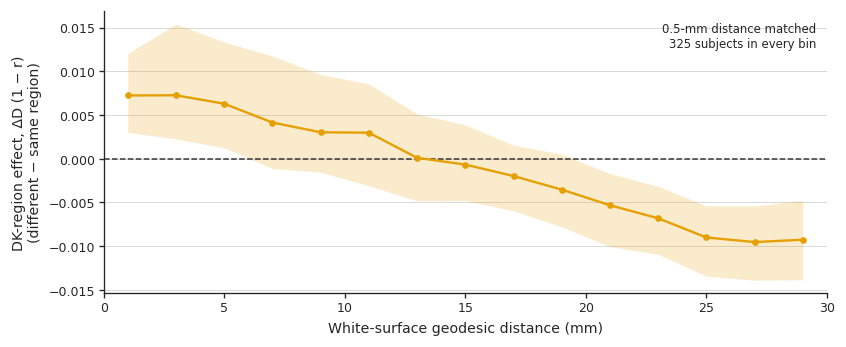

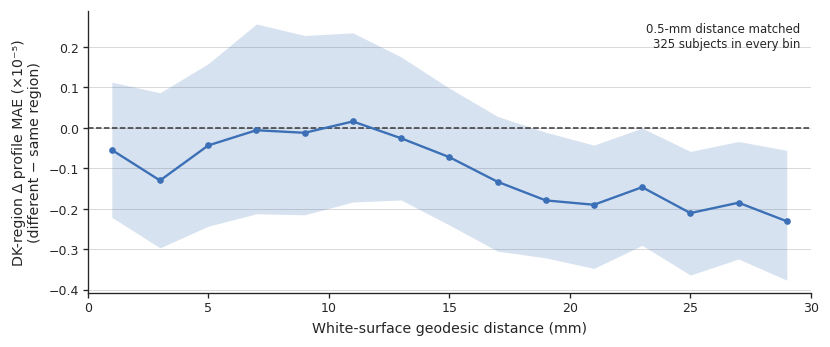

In [9]:
dk_status = json.loads(
    (DK_ALL_PAIRS_DIR / 'figure4_dk_all_pairs_status.json').read_text()
)
dk_group = pd.read_csv(
    DK_ALL_PAIRS_DIR / 'figure4_dk_all_pairs_group_summary.csv'
).sort_values('distance_bin_index')
dk_subject = pd.read_csv(
    DK_ALL_PAIRS_DIR / 'figure4_dk_all_pairs_subject_bins.csv'
)

near_subject = (
    dk_subject.loc[dk_subject['distance_bin_index'].lt(5)]
    .groupby('subject_id')['across_minus_within']
    .mean()
)
rng = np.random.default_rng(20261021)
near_boot = np.median(
    rng.choice(
        near_subject.to_numpy(),
        size=(10_000, len(near_subject)),
        replace=True,
    ),
    axis=1,
)
near_mae_subject = (
    dk_subject.loc[dk_subject['distance_bin_index'].lt(5)]
    .groupby('subject_id')['across_minus_within_mae']
    .mean()
)
near_mae_boot = np.median(
    rng.choice(
        near_mae_subject.to_numpy(),
        size=(10_000, len(near_mae_subject)),
        replace=True,
    ),
    axis=1,
)
display(Markdown(
    f"**All fixed-pair, region-balanced DK analysis.** "
    f"{dk_status['subjects_completed']}/{dk_status['subjects_expected']} subjects; "
    f"{dk_status['fixed_pair_count']:,} fixed pairs; "
    f"0–10-mm mean $\\Delta D$ median = {near_subject.median():.4f} "
    f"(IQR {near_subject.quantile(.25):.4f}–{near_subject.quantile(.75):.4f}; "
    f"bootstrap 95% CI {np.quantile(near_boot, .025):.4f}–"
    f"{np.quantile(near_boot, .975):.4f}); "
    f"{(near_subject > 0).sum()}/{len(near_subject)} subjects positive."
))
display(dk_group[[
    'distance_bin', 'n_subjects', 'delta_group_median',
    'delta_q25', 'delta_q75', 'delta_bootstrap_ci95_low',
    'delta_bootstrap_ci95_high', 'distance_difference_median_mm',
    'matched_region_count_median_subject',
    'within_pair_count_total', 'across_pair_count_total',
]])

display(Markdown(
    f"**Complementary profile MAE.** The 0–10-mm mean paired MAE difference "
    f"is {1e5 * near_mae_subject.median():.4f} ×10⁻⁵ "
    f"(IQR {1e5 * near_mae_subject.quantile(.25):.4f}–"
    f"{1e5 * near_mae_subject.quantile(.75):.4f}; bootstrap 95% CI "
    f"{1e5 * np.quantile(near_mae_boot, .025):.4f}–"
    f"{1e5 * np.quantile(near_mae_boot, .975):.4f}); "
    f"{(near_mae_subject > 0).sum()}/{len(near_mae_subject)} subjects positive."
))
dk_mae_table = dk_group[[
    'distance_bin', 'n_subjects',
    'within_profile_mae_group_median',
    'across_profile_mae_group_median',
    'mae_delta_group_median', 'mae_delta_q25', 'mae_delta_q75',
    'mae_delta_bootstrap_ci95_low', 'mae_delta_bootstrap_ci95_high',
]].copy()
for column in dk_mae_table.columns[2:]:
    dk_mae_table[column] *= 1e5
display(dk_mae_table)

x = dk_group['distance_bin_index'].to_numpy(dtype=float) * 2 + 1
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.05))
ax.axhline(0, color=PALETTE['reference'], linewidth=.9, linestyle='--')
ax.plot(
    x, dk_group['delta_group_median'], marker='o', markersize=3,
    color=PALETTE['orange'], linewidth=1.4,
)
ax.fill_between(
    x, dk_group['delta_q25'], dk_group['delta_q75'],
    color=PALETTE['orange'], alpha=.2, linewidth=0,
)
ax.text(
    .985, .96,
    '0.5-mm distance matched\n325 subjects in every bin',
    transform=ax.transAxes, ha='right', va='top', fontsize=7,
)
ax.set(
    xlabel='White-surface geodesic distance (mm)',
    ylabel='DK-region effect, ΔD (1 − r)\n(different − same region)',
    xlim=(0, 30),
)
style_axes(ax, grid=True)
fig.subplots_adjust(left=.135, right=.985, bottom=.20, top=.97)
save_publication_figure(
    fig, FIGURE_DIR / 'Figure4D_all_pairs_dk_region_effect'
)
plt.show()

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.05))
ax.axhline(0, color=PALETTE['reference'], linewidth=.9, linestyle='--')
ax.plot(
    x, 1e5 * dk_group['mae_delta_group_median'],
    marker='o', markersize=3, color=PALETTE['blue'], linewidth=1.4,
)
ax.fill_between(
    x,
    1e5 * dk_group['mae_delta_q25'],
    1e5 * dk_group['mae_delta_q75'],
    color=PALETTE['blue'], alpha=.2, linewidth=0,
)
ax.text(
    .985, .96,
    '0.5-mm distance matched\n325 subjects in every bin',
    transform=ax.transAxes, ha='right', va='top', fontsize=7,
)
ax.set(
    xlabel='White-surface geodesic distance (mm)',
    ylabel='DK-region Δ profile MAE (×10⁻⁵)\n(different − same region)',
    xlim=(0, 30),
)
style_axes(ax, grid=True)
fig.subplots_adjust(left=.135, right=.985, bottom=.20, top=.97)
save_publication_figure(
    fig, FIGURE_DIR / 'Figure4D_all_pairs_dk_region_mae_effect'
)
plt.show()


### Bilateral region × distance diagnostic

Left–right consistency is audited before combining homologous regions. The main display combines hemispheres within each subject and matched 0.5-mm sub-bin, then calculates the subject-level region × 2-mm-bin effect; it does not average rows of the 68-region group heatmap. Available hemispheres receive equal weight, preventing the side with more pairs from dominating.

The metric is explicitly audited as profile dissimilarity, $\Delta(1-r)$; profile MAE is stored and analysed separately. Regions are ordered continuously by the median subject-level mean $\Delta(1-r)$ over 0–10 mm. The adjacent forest plot shows that effect and its subject-bootstrap 95% CI; dotted reference lines at $\pm0.01$ are visual effect-size guides, not significance categories. The dashed heatmap line marks 10 mm. Gray cells fail the prespecified 80% subject-coverage and 20-pairs-per-class thresholds.

Because several regions have much larger effects than the whole-cortex summary, caudal anterior cingulate, inferior temporal, temporal pole, and fusiform are audited separately. Within- and across-region curves are shown for bilateral, left, and right estimates, together with subject distributions, pair counts, distance-matching error, and the changing composition of across-region comparators. These diagnostics are not treated as primary regional biological effects.

**Hemisphere consistency audit.** Across 33 homologous regions meeting coverage in both hemispheres, the group 0–10-mm effects had Pearson $r=0.872$ and Spearman $\rho=0.859$; 93.9% had the same sign. Within subjects, the across-region left–right Spearman correlation had median 0.220 (IQR 0.101–0.368); 87.7% of 324 subjects were positive.

**Continuous effect-size ordering.** The median regional 0–10-mm effect ranges from -0.0813 to 0.0994; 487/510 region × distance cells pass formal coverage. CI sign is not used to create categorical labels.

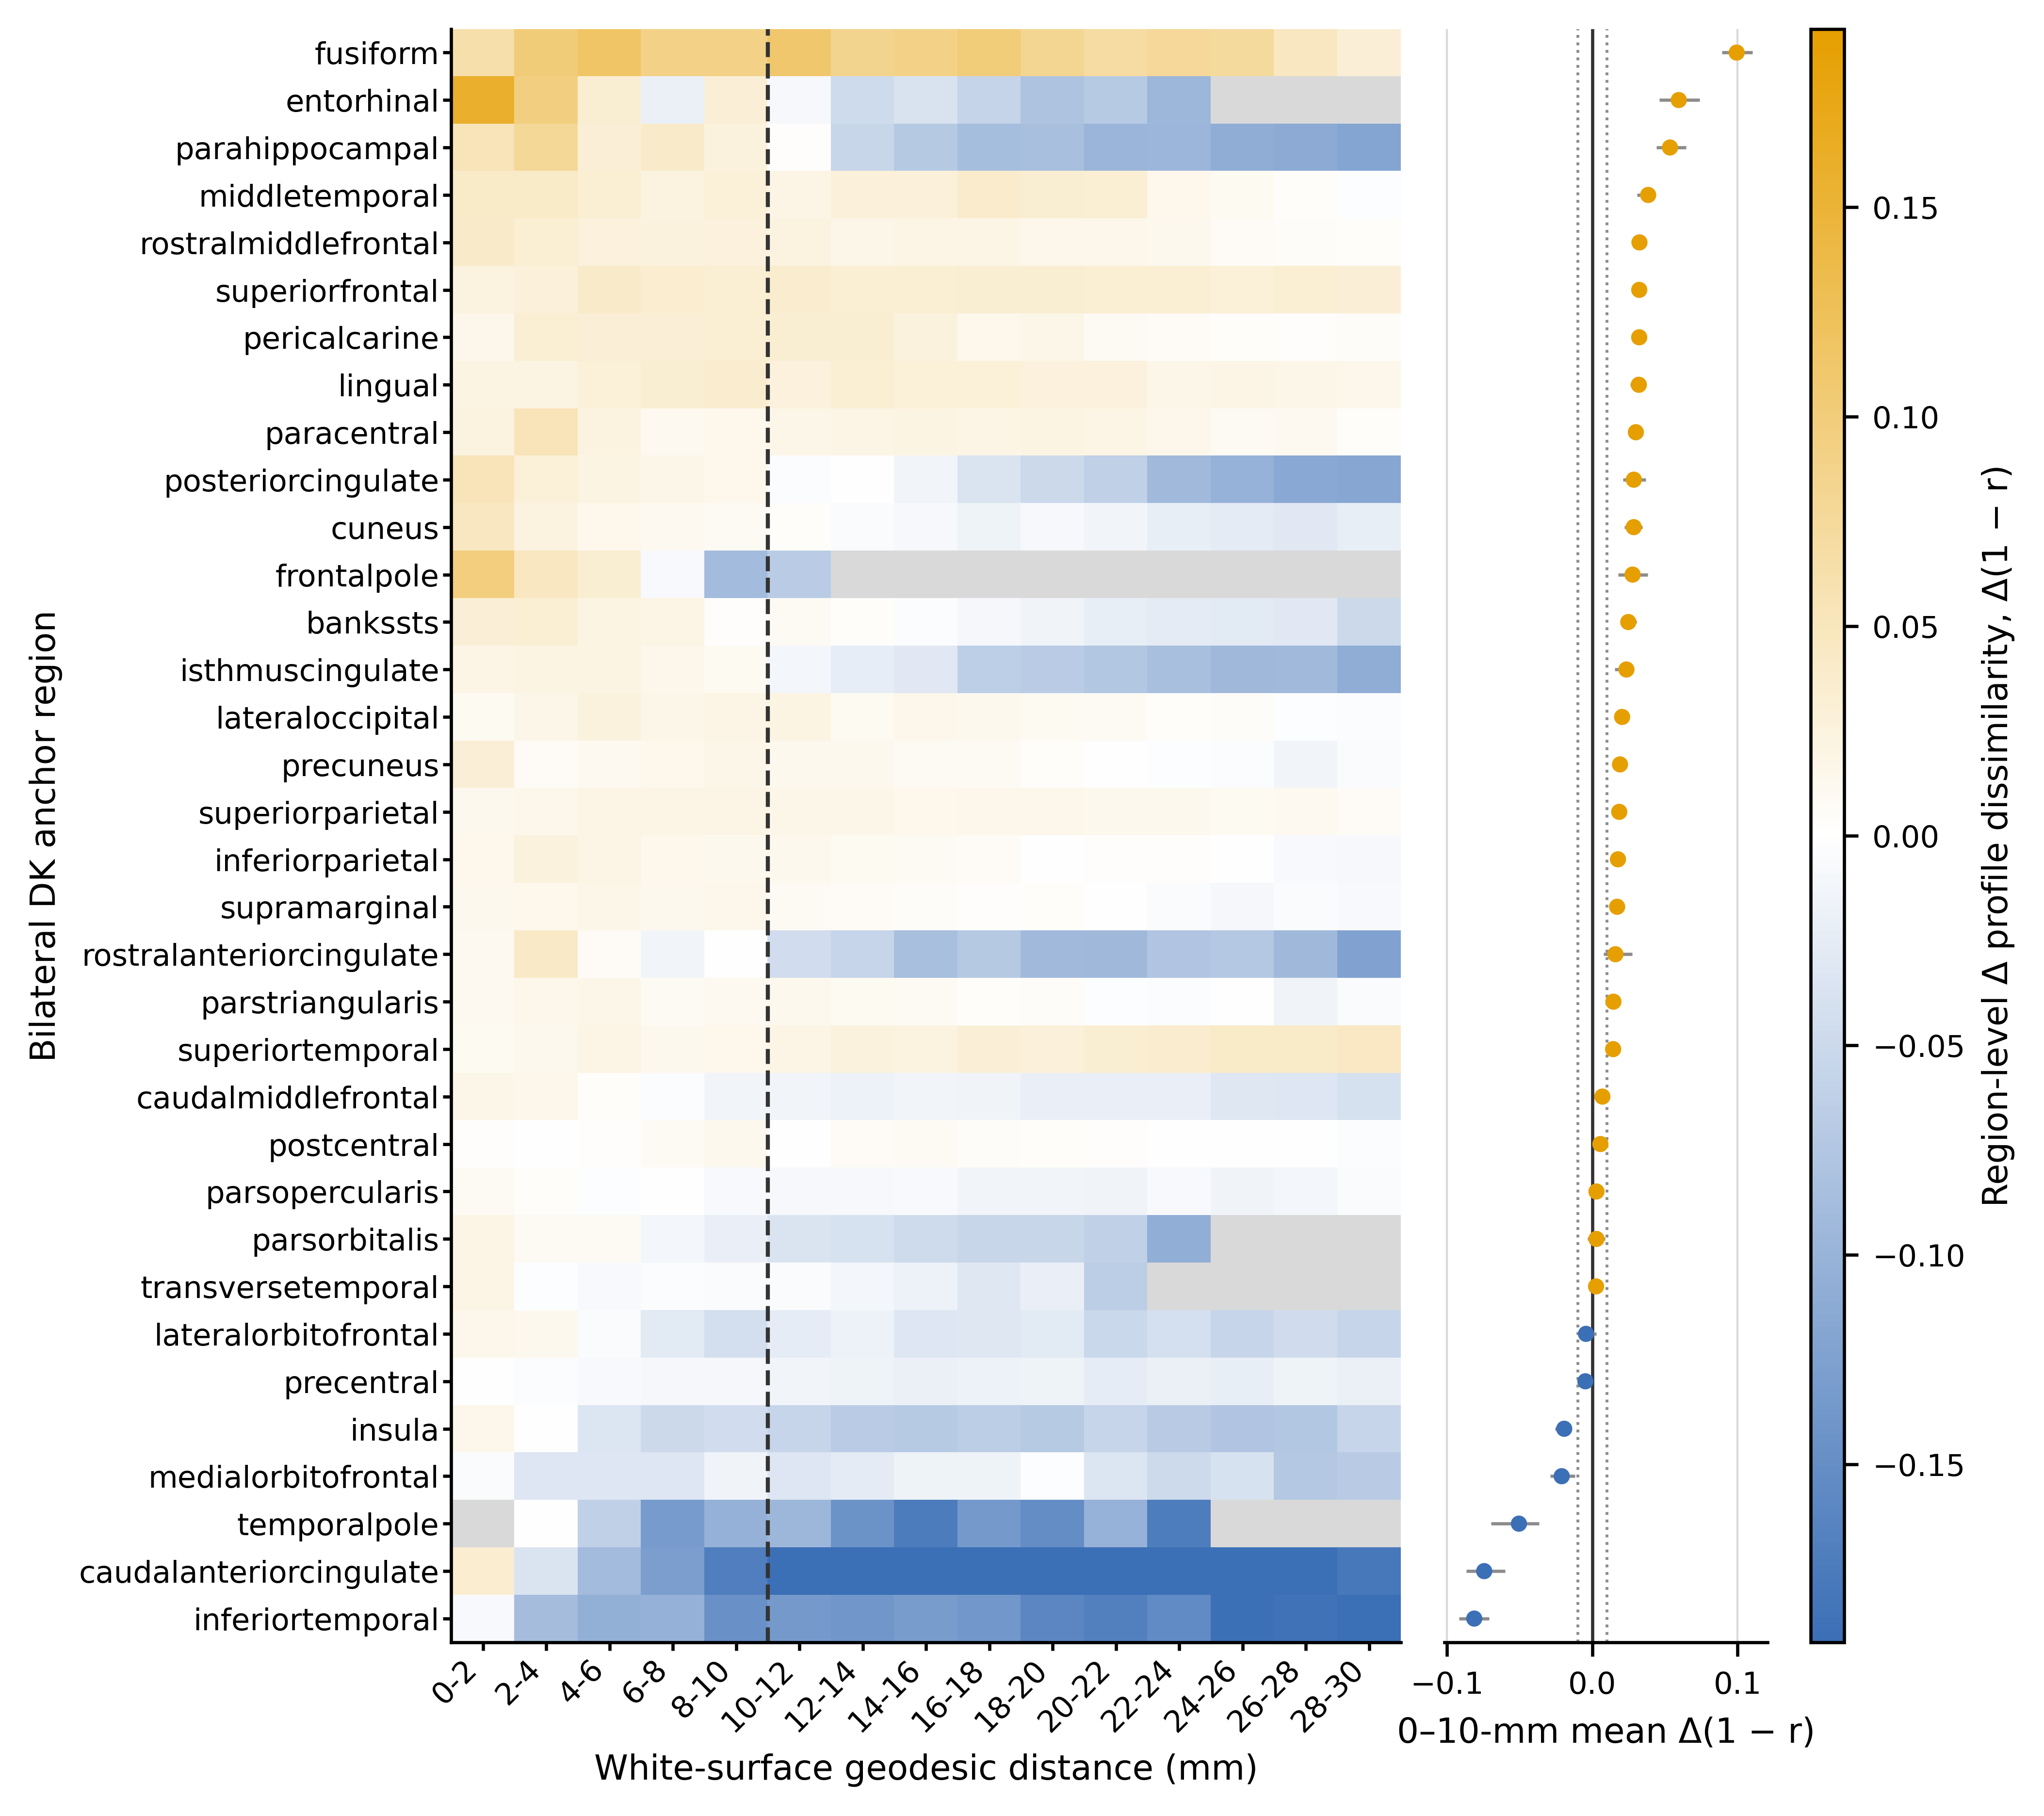

,dk_region,n_subjects,local_effect_median,local_effect_q25,local_effect_q75,bootstrap_ci95_low,bootstrap_ci95_high
0,fusiform,324,0.099436,0.050754,0.155498,0.089240,0.110462
1,entorhinal,323,0.059552,-0.021917,0.142032,0.046126,0.073892
2,parahippocampal,324,0.053514,-0.007686,0.110262,0.044070,0.064692
3,middletemporal,324,0.038497,0.010315,0.072593,0.030814,0.043658
4,rostralmiddlefrontal,324,0.032485,0.016830,0.054823,0.028895,0.036483
5,superiorfrontal,324,0.032343,0.015049,0.055285,0.028725,0.036766
6,pericalcarine,324,0.032310,0.015144,0.067691,0.028601,0.037346
7,lingual,324,0.032058,0.011219,0.066032,0.026279,0.034647
8,paracentral,324,0.030014,0.008210,0.059901,0.025100,0.034960
9,posteriorcingulate,325,0.028602,-0.004864,0.070343,0.021148,0.036683


**Metric audit.** profile_dissimilarity = 1 - Pearson profile correlation; MAE remains a separate metric. The plots below split each extreme effect into its within- and across-region curves before bilateral combination.

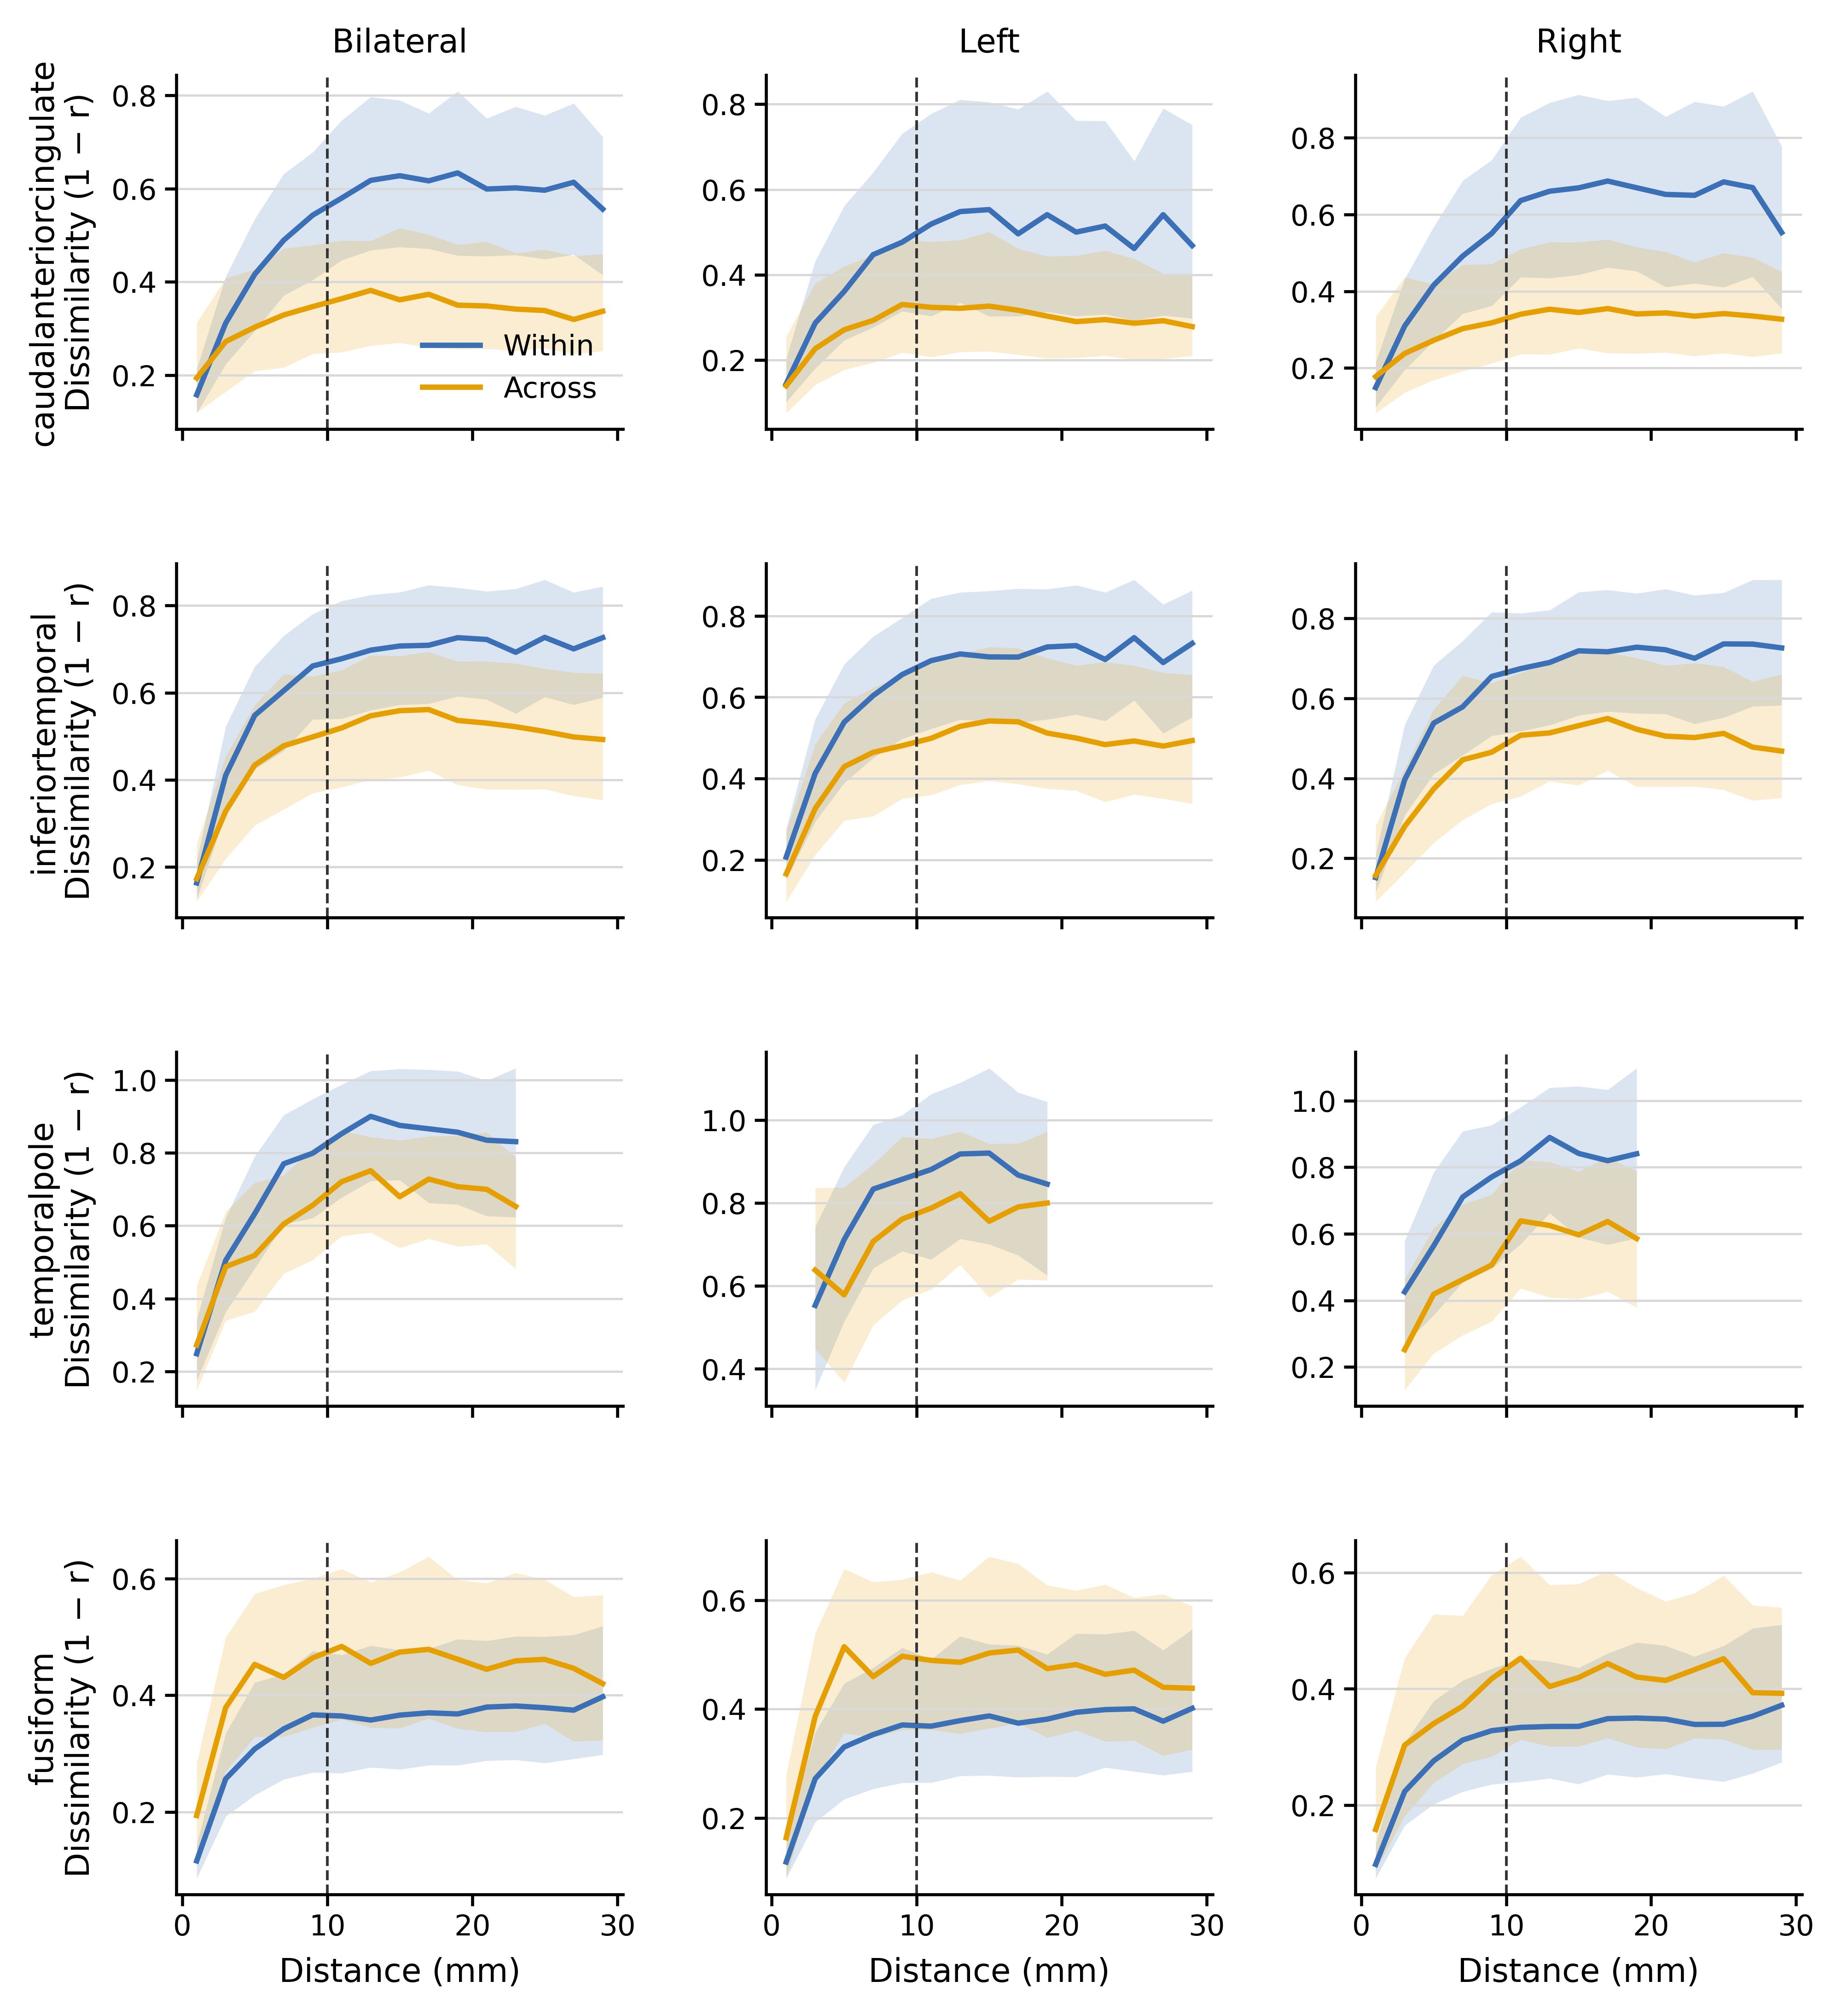

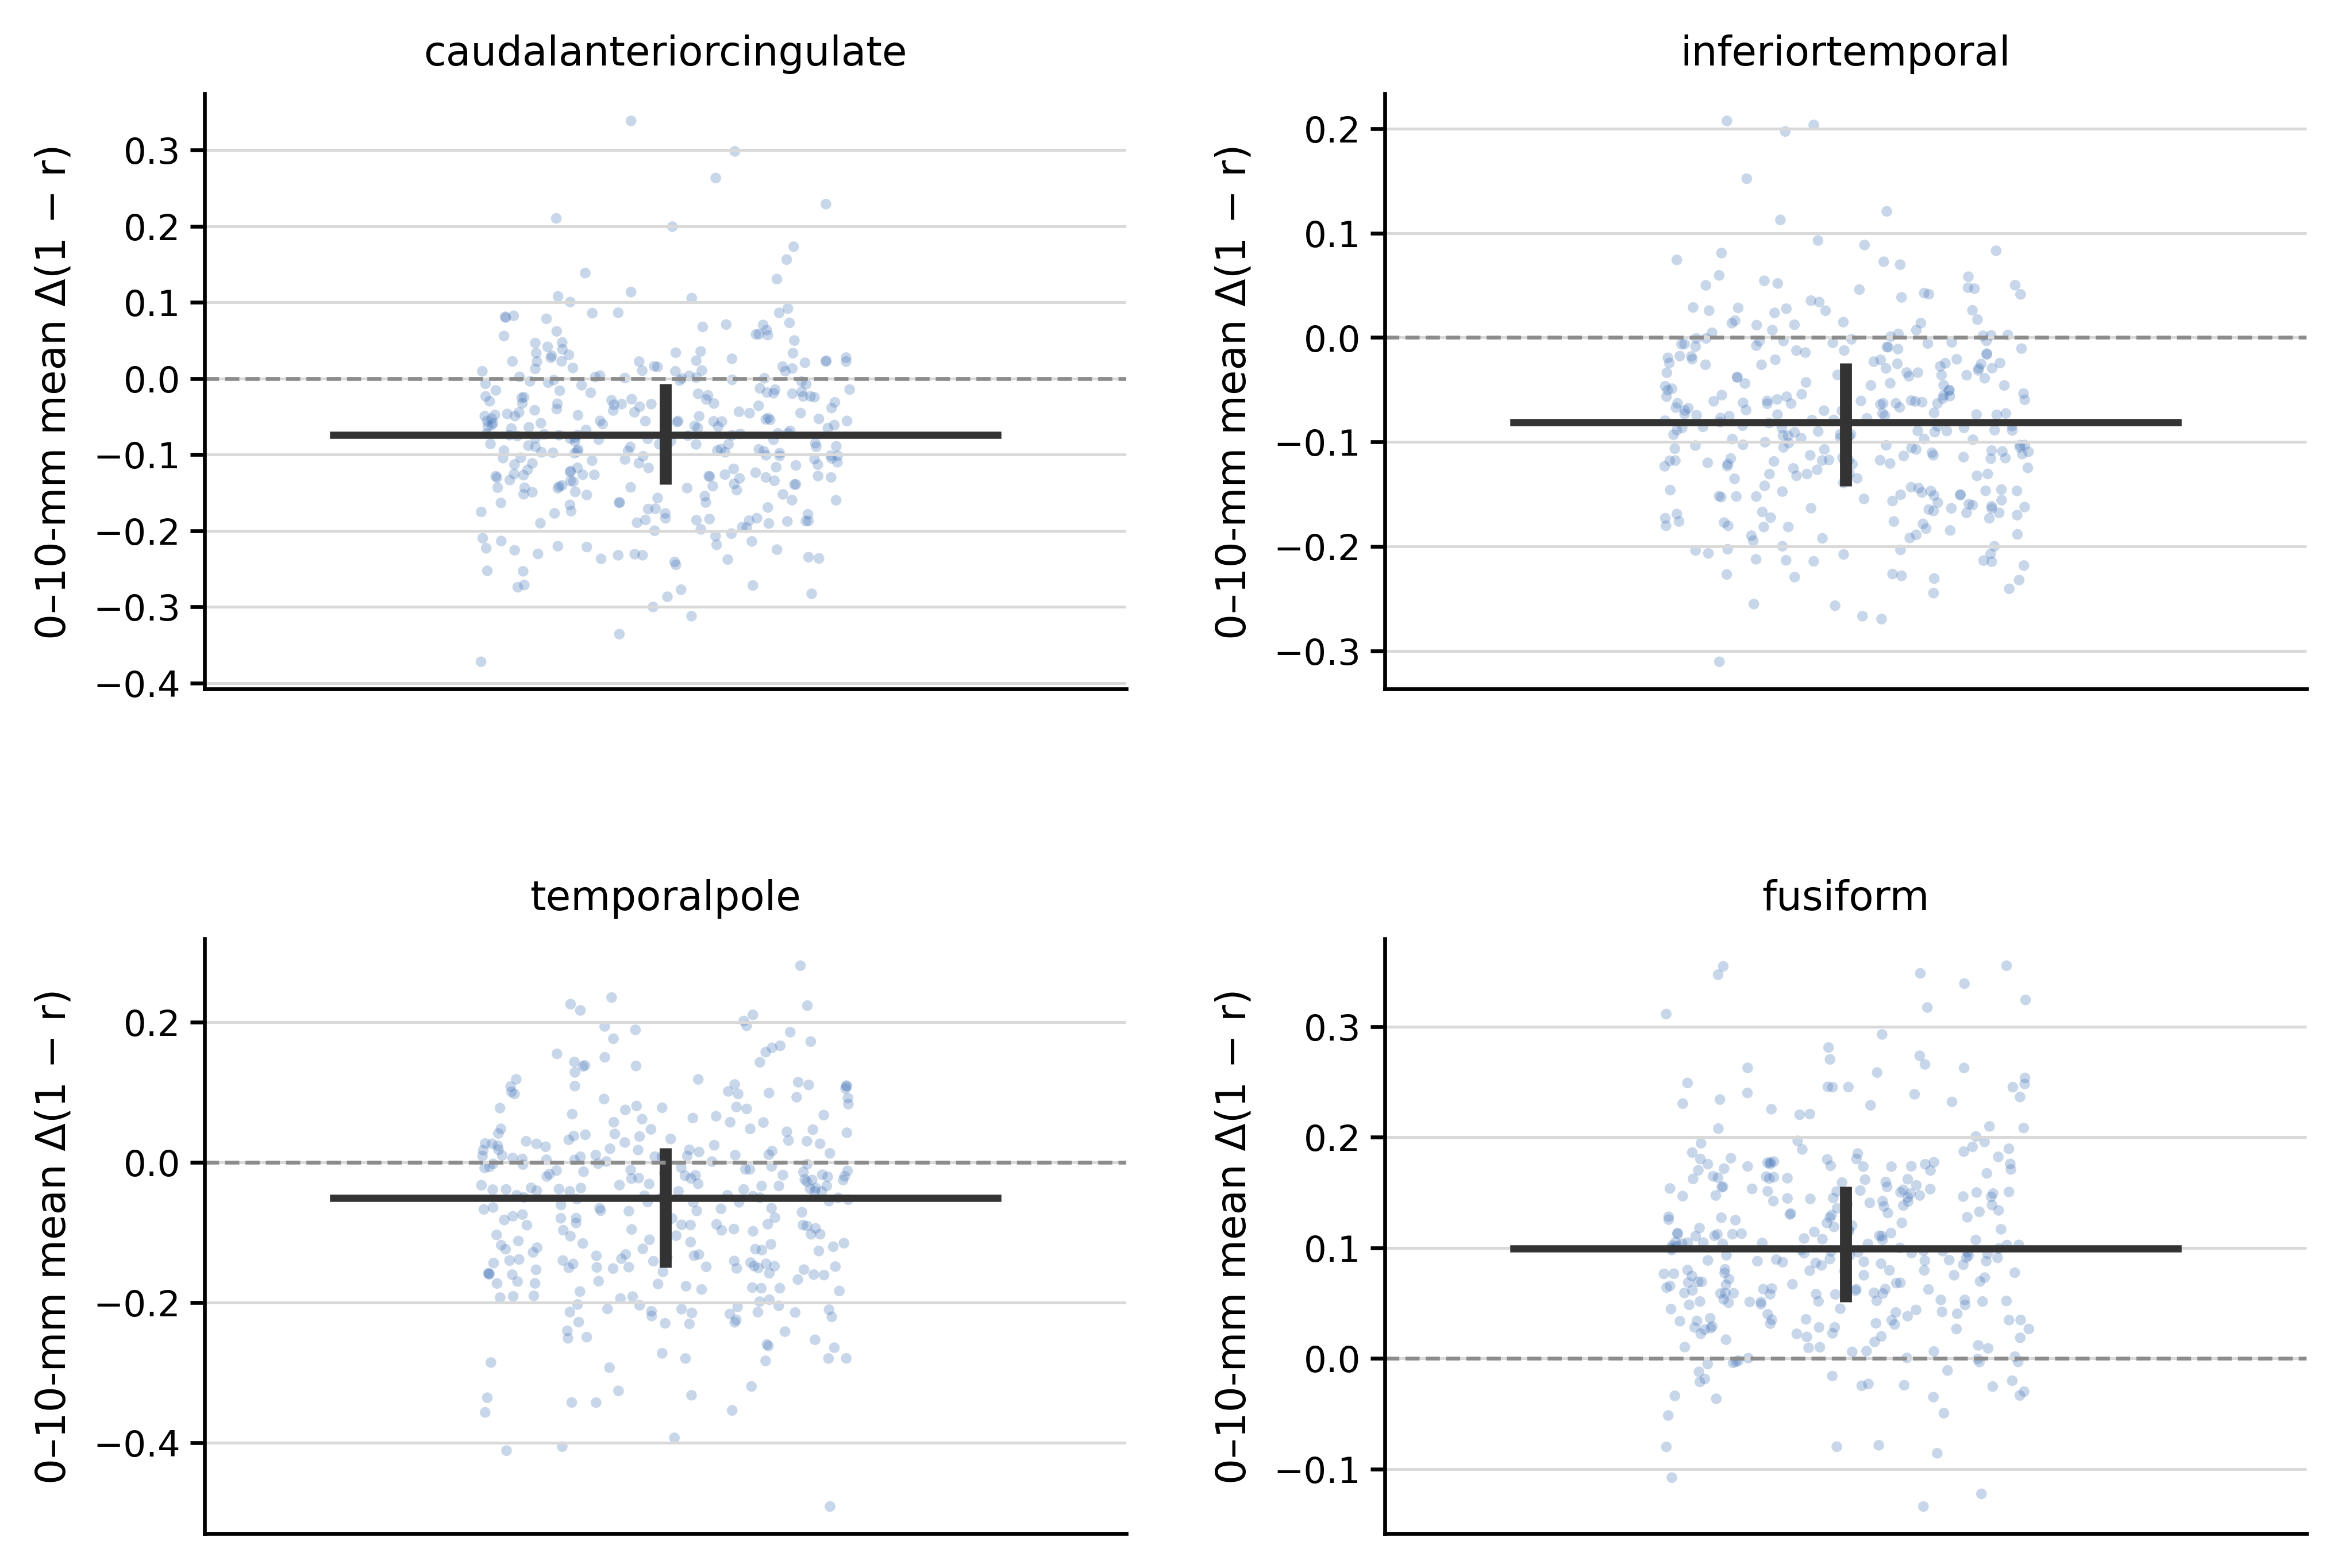

,dk_region,scope,n_subjects,local_effect_median,local_effect_q25,local_effect_q75,bootstrap_ci95_low,bootstrap_ci95_high,positive_subject_fraction
0,caudalanteriorcingulate,bilateral,324,-0.074438,-0.139123,-0.007336,-0.087434,-0.059933,0.228395
1,caudalanteriorcingulate,lh,324,-0.059665,-0.144994,0.011321,-0.074564,-0.043219,0.302469
2,caudalanteriorcingulate,rh,324,-0.080410,-0.175382,0.004642,-0.104620,-0.062223,0.262346
9,fusiform,bilateral,324,0.099436,0.050754,0.155498,0.089240,0.110462,0.904321
10,fusiform,lh,323,0.099934,0.027205,0.187160,0.088154,0.122129,0.854489
11,fusiform,rh,323,0.077910,0.011920,0.151891,0.062099,0.091633,0.801858
3,inferiortemporal,bilateral,324,-0.081298,-0.142265,-0.024434,-0.092644,-0.070174,0.154321
4,inferiortemporal,lh,323,-0.079891,-0.146610,-0.019292,-0.099828,-0.062458,0.201238
5,inferiortemporal,rh,323,-0.096889,-0.162896,-0.018750,-0.113935,-0.079982,0.195046
6,temporalpole,bilateral,323,-0.050528,-0.150255,0.020866,-0.071220,-0.036662,0.321981


,dk_region,scope,minimum_subjects,within_pair_count_0_10,across_pair_count_0_10,distance_error_median_mm
0,caudalanteriorcingulate,bilateral,324,935309,241935,0.045407
1,caudalanteriorcingulate,lh,323,491173,140002,0.047763
2,caudalanteriorcingulate,rh,322,443816,101821,0.061734
3,fusiform,bilateral,323,2815676,524271,0.034466
4,fusiform,lh,321,1383984,280054,0.044805
5,fusiform,rh,321,1430784,244108,0.031843
6,inferiortemporal,bilateral,324,2539312,496491,0.031594
7,inferiortemporal,lh,323,1528170,302837,0.027605
8,inferiortemporal,rh,323,1010606,193551,0.030327
9,temporalpole,bilateral,236,470233,156258,0.038331


**Across-region comparator composition.** The table lists the three most frequent target DK regions for each anchor region, hemisphere, and distance range.

,anchor_region,hemisphere,distance_range,neighbor_region,pair_count,pair_fraction,rank_within_range
2,caudalanteriorcingulate,lh,0-10 mm,superiorfrontal,229,0.409660,1
0,caudalanteriorcingulate,lh,0-10 mm,posteriorcingulate,213,0.381038,2
1,caudalanteriorcingulate,lh,0-10 mm,rostralanteriorcingulate,117,0.209302,3
7,caudalanteriorcingulate,lh,10-30 mm,superiorfrontal,2246,0.565031,1
5,caudalanteriorcingulate,lh,10-30 mm,posteriorcingulate,964,0.242516,2
6,caudalanteriorcingulate,lh,10-30 mm,rostralanteriorcingulate,740,0.186164,3
10,caudalanteriorcingulate,rh,0-10 mm,superiorfrontal,188,0.443396,1
8,caudalanteriorcingulate,rh,0-10 mm,posteriorcingulate,168,0.396226,2
9,caudalanteriorcingulate,rh,0-10 mm,rostralanteriorcingulate,68,0.160377,3
15,caudalanteriorcingulate,rh,10-30 mm,superiorfrontal,1930,0.549858,1


### Supplementary diagnostic: hemisphere-specific region × distance heterogeneity

The original 68 × 15 effect heatmap and coverage heatmap are retained to show lateralization and all cells failing the prespecified coverage rule.

**Hemisphere-specific coverage.** 937/1020 cells pass; 46/68 rows support all 15 bins.

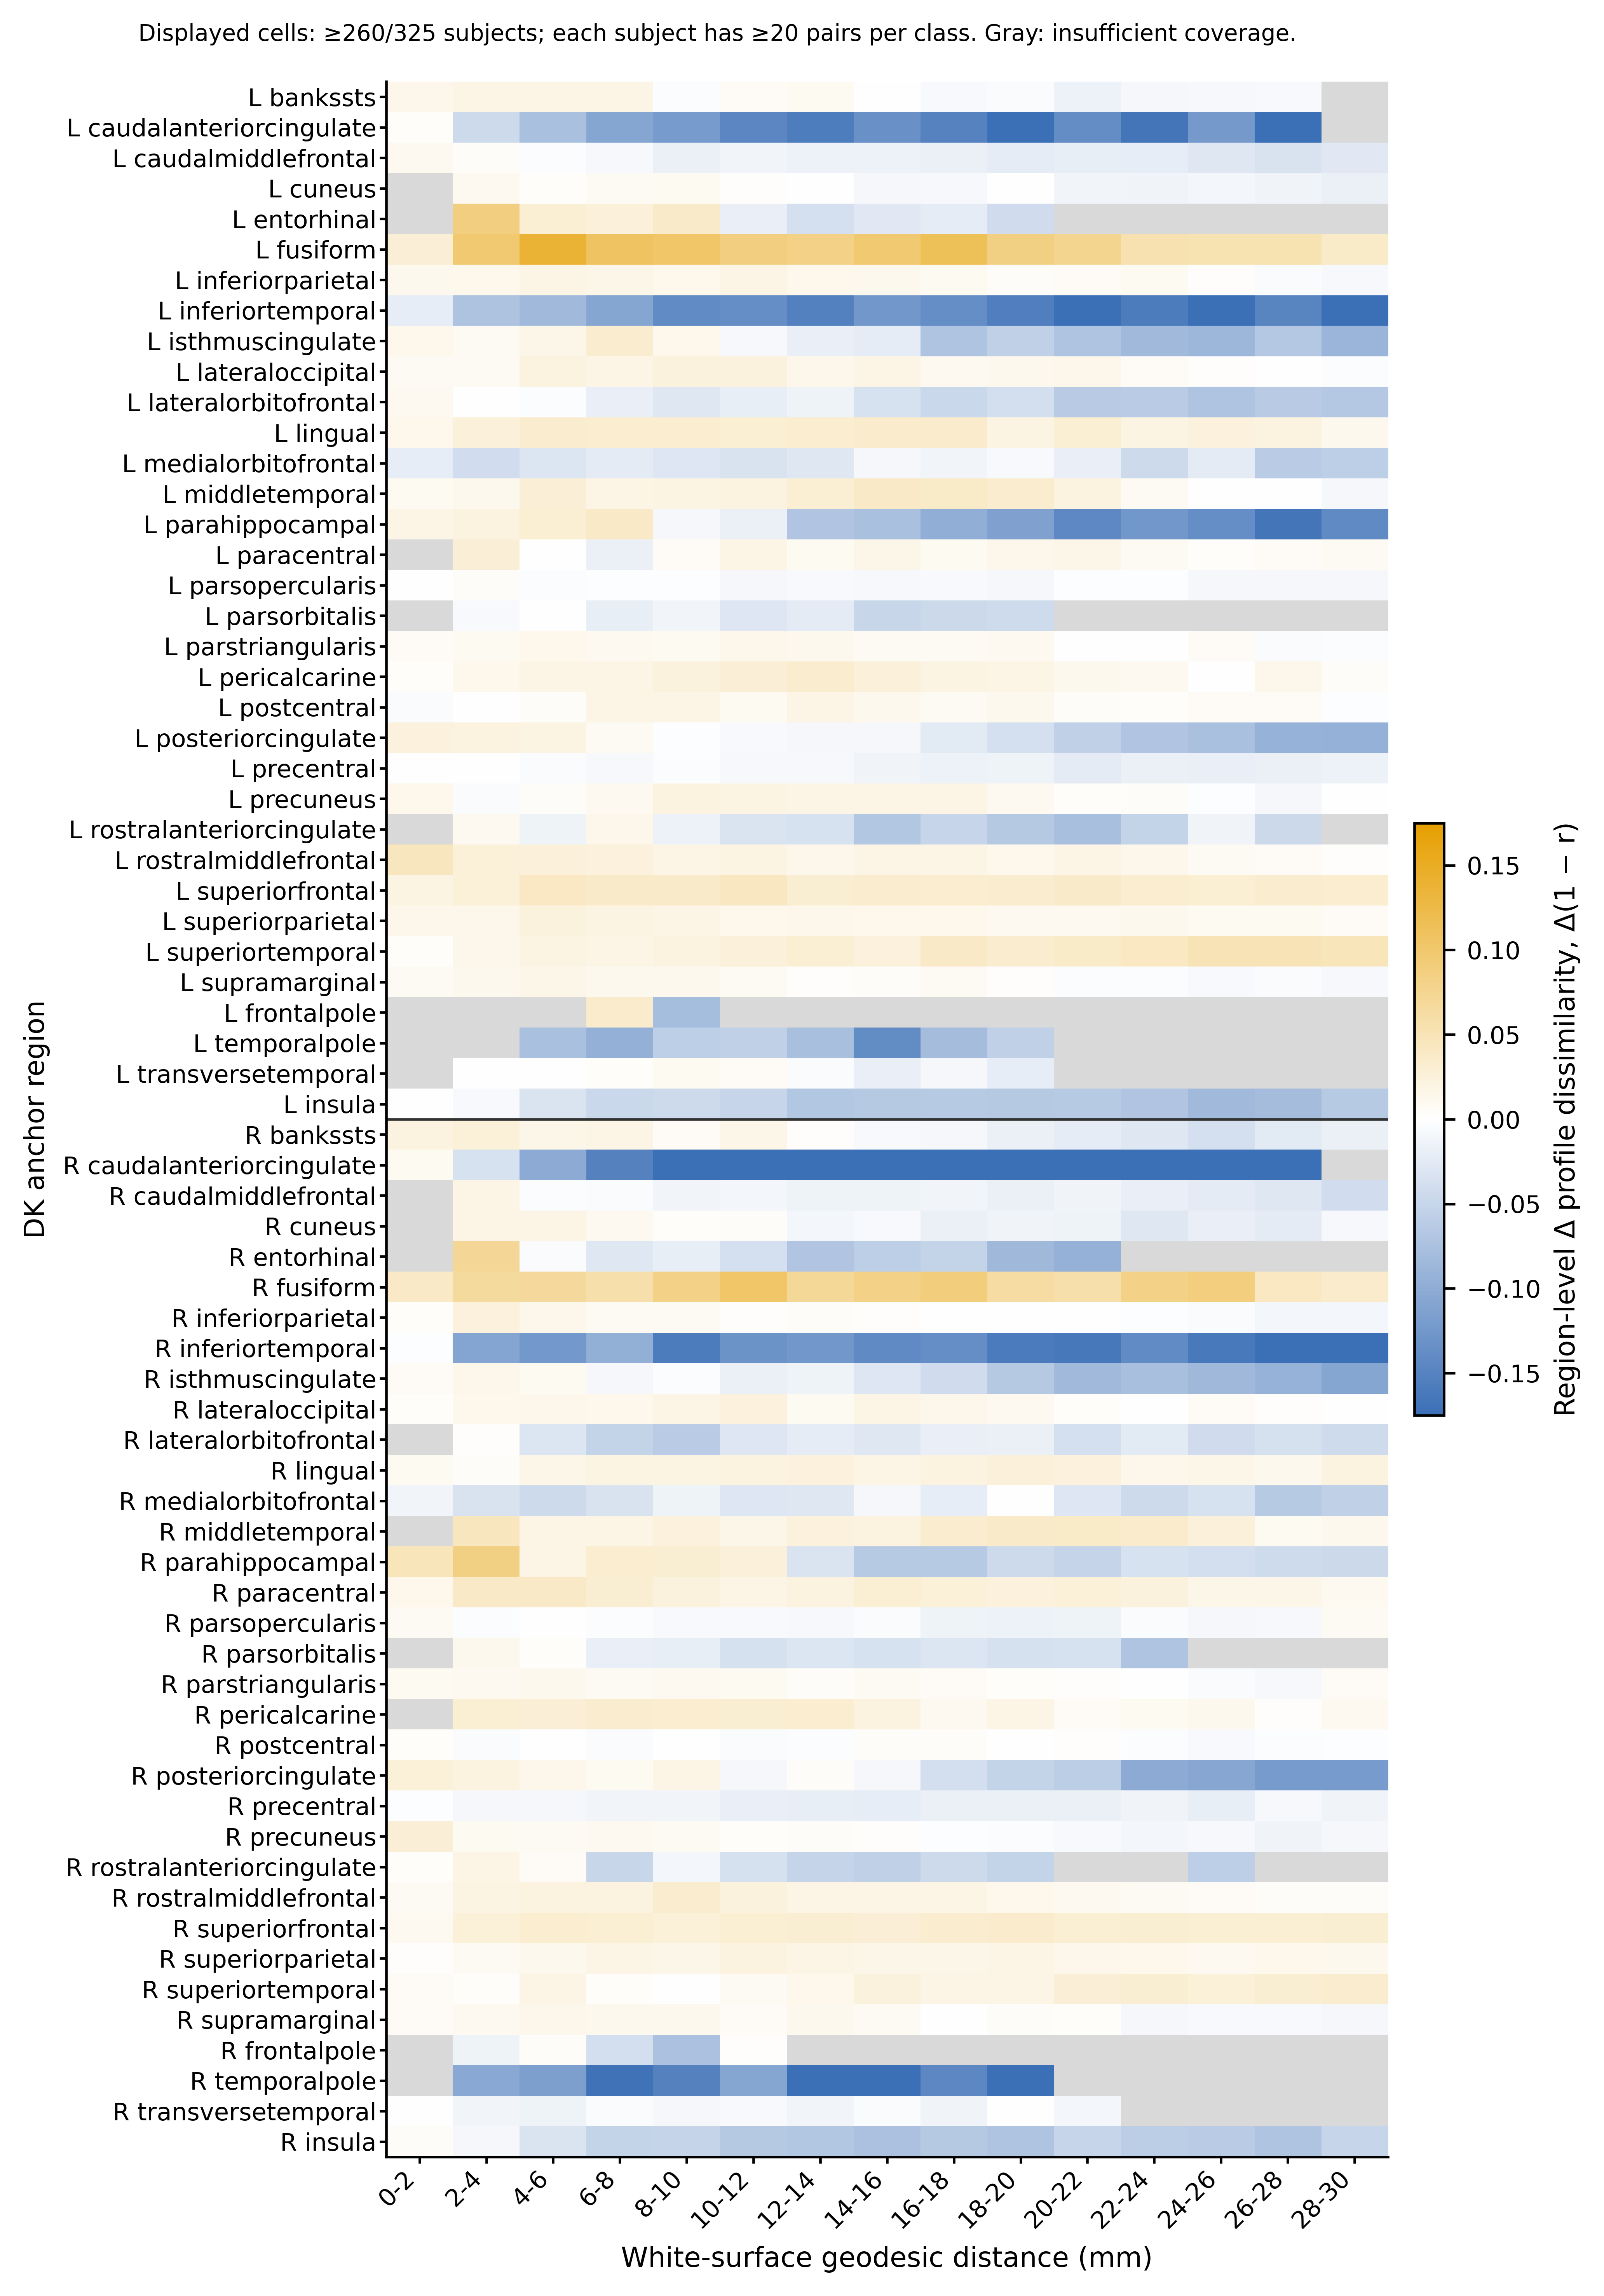

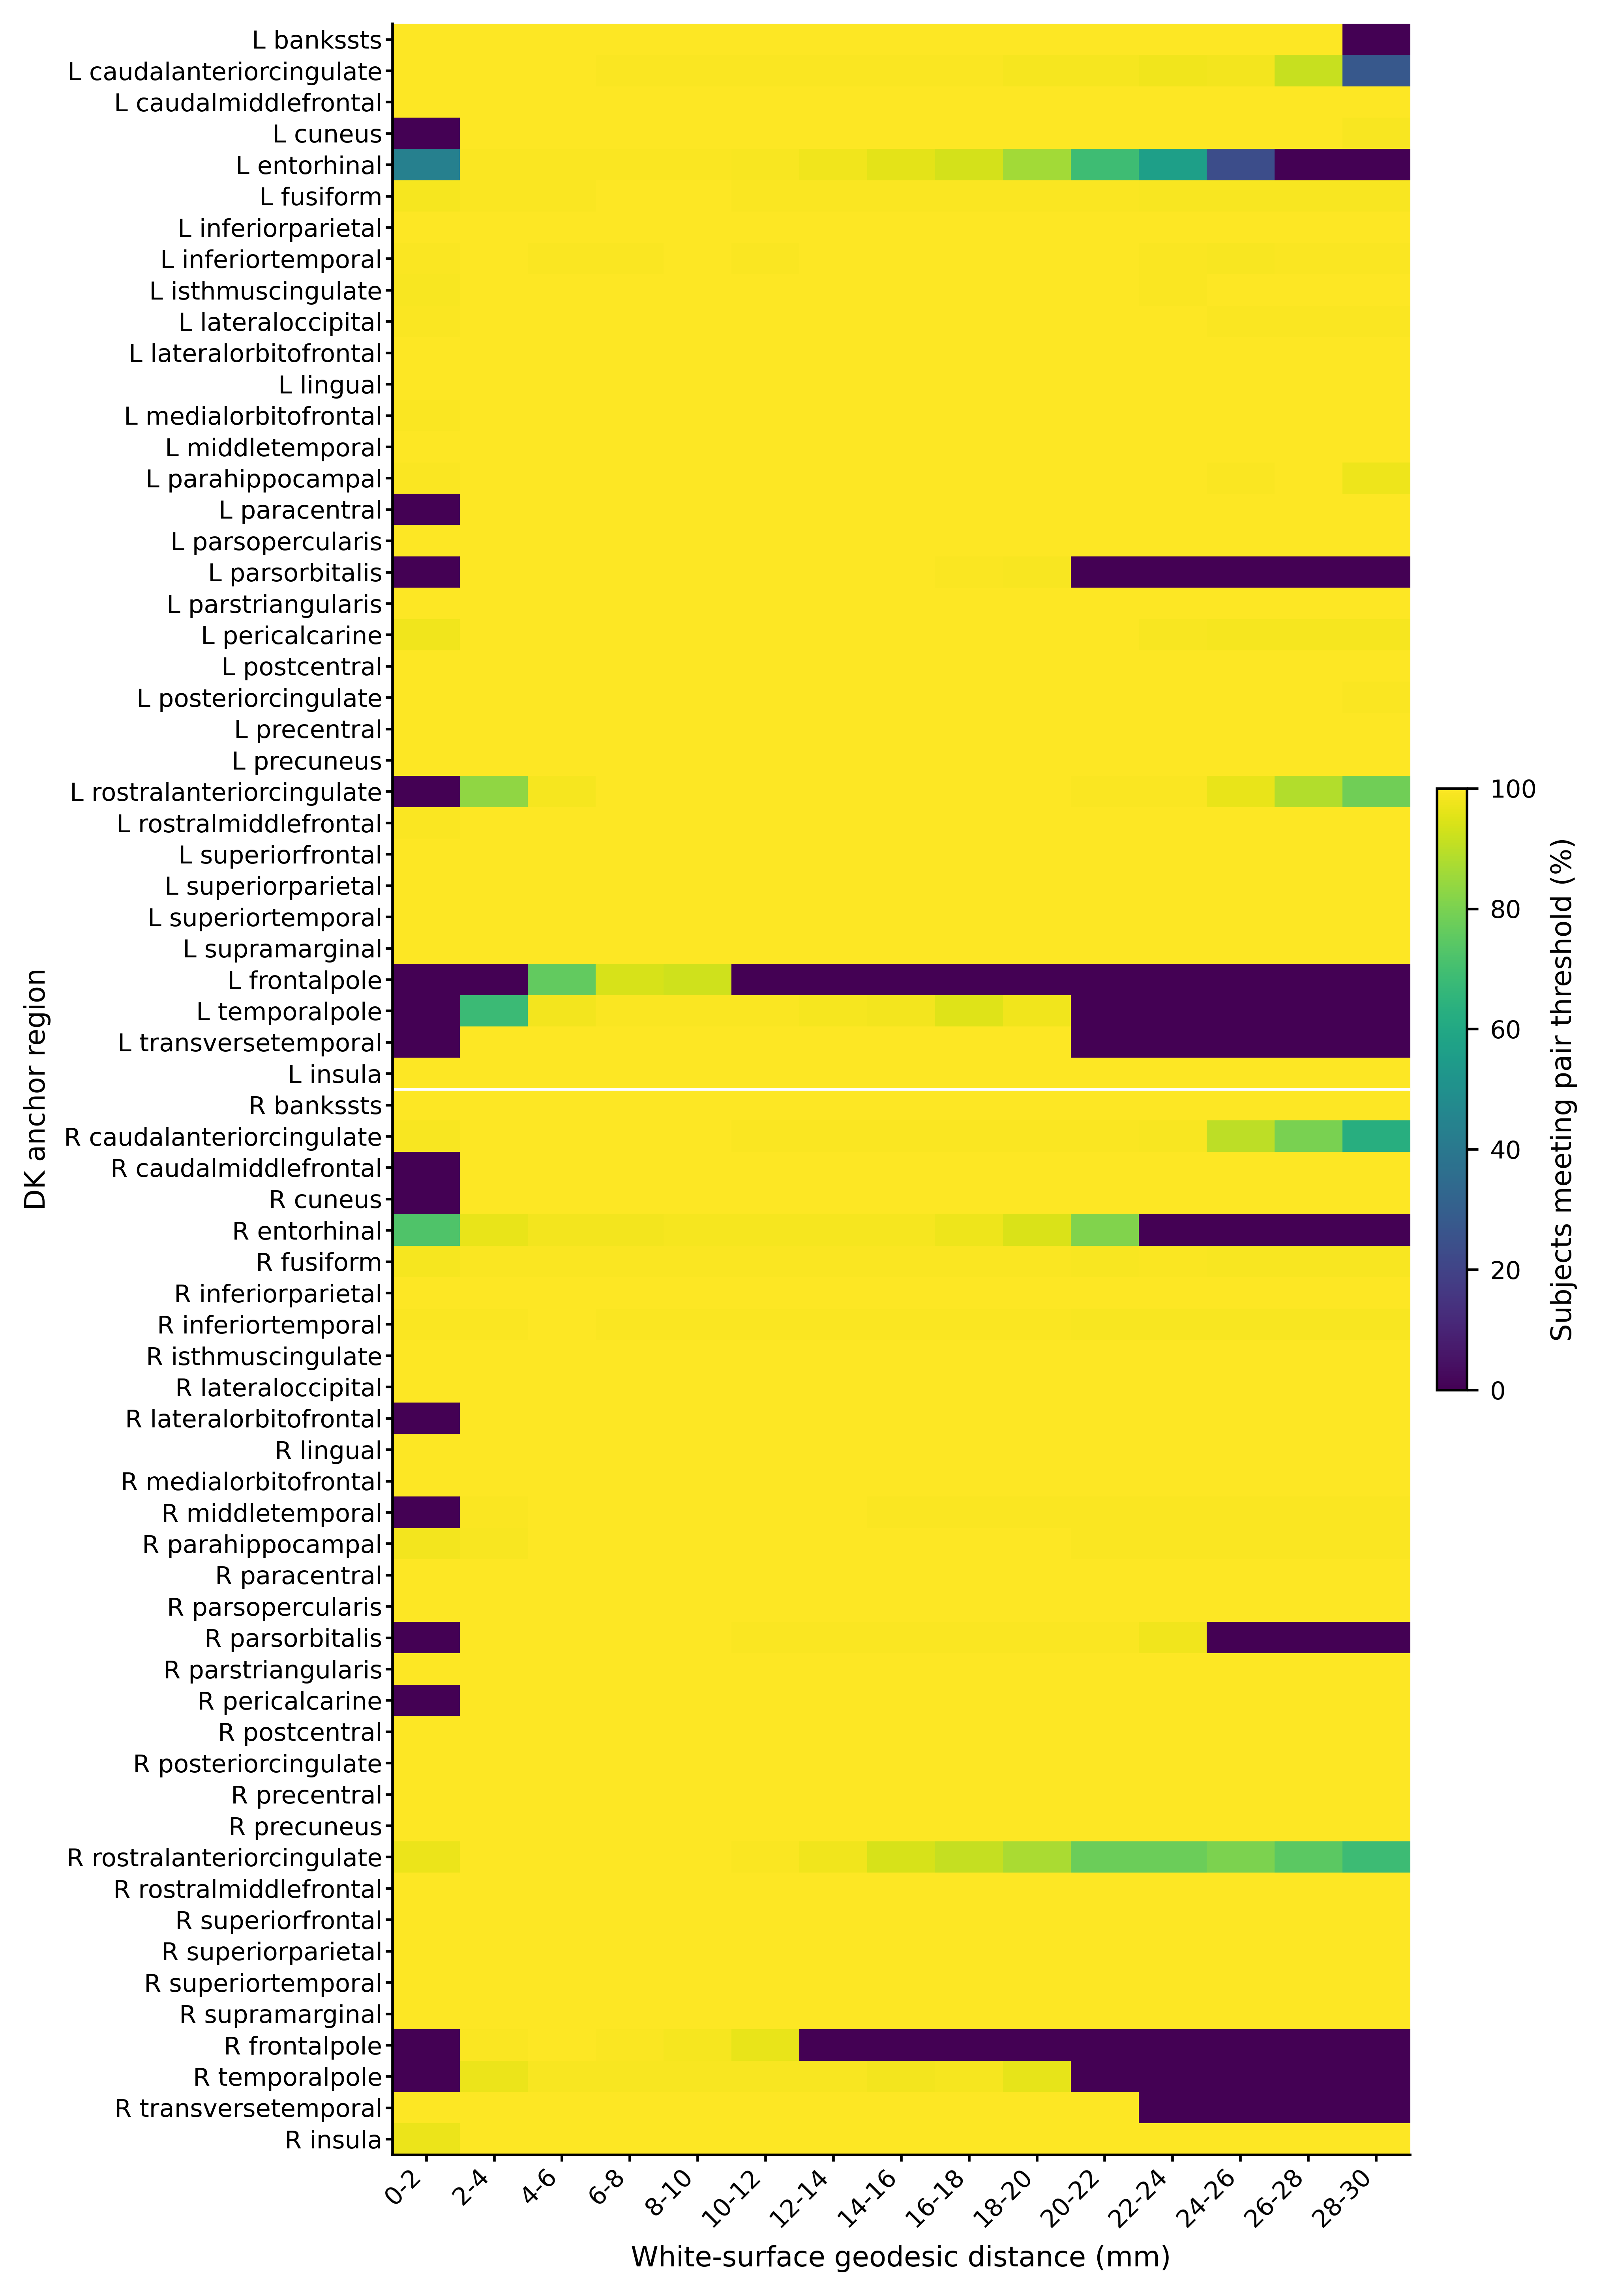

,region_display,valid_distance_bins,minimum_eligible_subjects_across_bins,maximum_eligible_subjects_across_bins,within_pair_count_total,across_pair_count_total,distance_error_0_10_median_mm,max_supported_within_distance_mm
0,L bankssts,14,0,324,1261763,1548495,0.037550,29.999299
1,L caudalanteriorcingulate,14,90,324,798323,1095563,0.041665,29.957462
2,L caudalmiddlefrontal,15,324,324,3273399,2546501,0.031871,29.997200
3,L cuneus,14,0,324,1018926,1185039,0.021206,29.946001
4,L entorhinal,9,0,323,449719,591804,0.045860,29.466258
...,...,...,...,...,...,...,...,...
63,R supramarginal,15,324,324,7390305,3848129,0.022393,29.997623
64,R frontalpole,5,0,324,141856,312937,0.053797,21.835967
65,R temporalpole,9,0,322,385022,544743,0.034632,26.890942
66,R transversetemporal,11,0,324,435658,789362,0.075726,27.425759


In [10]:
bilateral_status = json.loads(
    (DK_ALL_PAIRS_DIR / 'figure4D_bilateral_region_heatmap_status.json').read_text()
)
bilateral_effects = pd.read_csv(
    DK_ALL_PAIRS_DIR / 'figure4D_bilateral_region_local_effect_summary.csv'
)
consistency = bilateral_status['hemisphere_consistency']
display(Markdown(
    f"**Hemisphere consistency audit.** Across "
    f"{consistency['group_level_homologous_regions']} homologous regions meeting "
    f"coverage in both hemispheres, the group 0–10-mm effects had Pearson "
    f"$r={consistency['group_level_pearson_r']:.3f}$ and Spearman "
    f"$\\rho={consistency['group_level_spearman_rho']:.3f}$; "
    f"{100 * consistency['group_level_same_sign_fraction']:.1f}% had the same sign. "
    f"Within subjects, the across-region left–right Spearman correlation had "
    f"median {consistency['subject_level_spearman_median']:.3f} "
    f"(IQR {consistency['subject_level_spearman_q25']:.3f}–"
    f"{consistency['subject_level_spearman_q75']:.3f}); "
    f"{100 * consistency['subject_level_positive_spearman_fraction']:.1f}% "
    f"of {consistency['subject_level_n']} subjects were positive."
))
display(Markdown(
    f"**Continuous effect-size ordering.** The median regional 0–10-mm effect "
    f"ranges from {bilateral_status['local_effect_median_min']:.4f} to "
    f"{bilateral_status['local_effect_median_max']:.4f}; "
    f"{bilateral_status['formal_cells']}/{bilateral_status['total_cells']} "
    f"region × distance cells pass formal coverage. CI sign is not used to "
    f"create categorical labels."
))
display(Image(filename=str(
    FIGURE_DIR / 'Figure4D_bilateral_region_distance_effect_heatmap.png'
)))
display(bilateral_effects[[
    'dk_region', 'n_subjects', 'local_effect_median',
    'local_effect_q25', 'local_effect_q75',
    'bootstrap_ci95_low', 'bootstrap_ci95_high',
]])

extreme_status = json.loads(
    (DK_ALL_PAIRS_DIR / 'figure4D_extreme_region_audit_status.json').read_text()
)
extreme_local = pd.read_csv(
    DK_ALL_PAIRS_DIR / 'figure4D_extreme_region_local_effects.csv'
)
extreme_curve = pd.read_csv(
    DK_ALL_PAIRS_DIR / 'figure4D_extreme_region_curve_audit.csv'
)
neighbor_ranges = pd.read_csv(
    DK_ALL_PAIRS_DIR / 'figure4D_extreme_region_across_neighbor_composition_ranges.csv'
)
display(Markdown(
    f"**Metric audit.** {extreme_status['metric_confirmed']}; MAE remains a "
    f"separate metric. The plots below split each extreme effect into its "
    f"within- and across-region curves before bilateral combination."
))
display(Image(filename=str(
    FIGURE_DIR / 'Figure4D_extreme_regions_within_across.png'
)))
display(Image(filename=str(
    FIGURE_DIR / 'Figure4D_extreme_regions_subject_distributions.png'
)))
display(extreme_local[[
    'dk_region', 'scope', 'n_subjects', 'local_effect_median',
    'local_effect_q25', 'local_effect_q75',
    'bootstrap_ci95_low', 'bootstrap_ci95_high',
    'positive_subject_fraction',
]].sort_values(['dk_region', 'scope']))
near_qc = (
    extreme_curve.loc[extreme_curve['distance_bin_index'].lt(5)]
    .groupby(['dk_region', 'scope'], as_index=False)
    .agg(
        minimum_subjects=('n_subjects', 'min'),
        within_pair_count_0_10=('within_pair_count_total', 'sum'),
        across_pair_count_0_10=('across_pair_count_total', 'sum'),
        distance_error_median_mm=('distance_error_median_mm', 'median'),
    )
)
display(near_qc)
display(Markdown(
    '**Across-region comparator composition.** The table lists the three most '
    'frequent target DK regions for each anchor region, hemisphere, and distance range.'
))
display(
    neighbor_ranges.loc[neighbor_ranges['rank_within_range'].le(3), [
        'anchor_region', 'hemisphere', 'distance_range',
        'neighbor_region', 'pair_count', 'pair_fraction', 'rank_within_range',
    ]].sort_values([
        'anchor_region', 'hemisphere', 'distance_range', 'rank_within_range'
    ])
)

display(Markdown(
    '### Supplementary diagnostic: hemisphere-specific region × distance heterogeneity\n\n'
    'The original 68 × 15 effect heatmap and coverage heatmap are retained to '
    'show lateralization and all cells failing the prespecified coverage rule.'
))
region_heatmap_status = json.loads(
    (DK_ALL_PAIRS_DIR / 'figure4D_region_heatmap_status.json').read_text()
)
region_coverage = pd.read_csv(
    DK_ALL_PAIRS_DIR / 'figure4D_region_coverage_summary.csv'
)
display(Markdown(
    f"**Hemisphere-specific coverage.** {region_heatmap_status['formal_cells']}/"
    f"{region_heatmap_status['total_cells']} cells pass; "
    f"{region_heatmap_status['regions_with_all_bins']}/68 rows support all 15 bins."
))
display(Image(filename=str(FIGURE_DIR / 'Figure4D_region_distance_effect_heatmap.png')))
display(Image(filename=str(FIGURE_DIR / 'Figure4D_region_distance_coverage_heatmap.png')))
display(region_coverage[[
    'region_display', 'valid_distance_bins',
    'minimum_eligible_subjects_across_bins',
    'maximum_eligible_subjects_across_bins',
    'within_pair_count_total', 'across_pair_count_total',
    'distance_error_0_10_median_mm',
    'max_supported_within_distance_mm',
]])


### Supplementary sensitivity: boundary-adjacent matched anchors

The earlier boundary-focused analysis is retained as a complementary sensitivity analysis. It restricts estimation to anchors that have both same-region and across-boundary neighbors and calculates the difference within the same anchor before subject-level aggregation. This controls anchor location more strictly, but answers the narrower question of whether crossing a nearby DK boundary produces a local discontinuity.

In [ ]:
boundary_summary = pd.read_csv(
    REAL_DIR / 'figure4_within_across_matched_group_summary.csv'
).sort_values('distance_bin_index')
display(boundary_summary[[
    'distance_bin', 'n_subjects', 'matched_anchor_count_total',
    'within_pair_count_total', 'across_pair_count_total',
]])

x = boundary_summary['distance_bin_index'] * 2 + 1
fig, (ax, count_ax) = plt.subplots(
    2, 1, figsize=(FIGURE_WIDTH_IN, 4.7), sharex=True,
    gridspec_kw={'height_ratios': [3, 1.35], 'hspace': 0.16},
)

ax.axhline(0, color=PALETTE['reference'], linewidth=0.9)
ax.plot(
    x, boundary_summary['delta_group_median'], marker='o',
    color=PALETTE['orange'],
)
ax.fill_between(
    x, boundary_summary['delta_q25'], boundary_summary['delta_q75'],
    color=PALETTE['orange'], alpha=0.2, linewidth=0,
)
ax.set_ylabel(
    'Matched-anchor Δ dissimilarity, Δ(1 − r)\n(across − within)'
)
style_axes(ax, grid=True)
ax.tick_params(labelbottom=False)

# Show anchor and pair counts on their respective scales.
count_ax.plot(
    x, boundary_summary['matched_anchor_count_median_subject'],
    marker='s', markersize=3, color=PALETTE['orange'],
    label='Matched anchors / subject',
)
count_ax.set_ylabel('Matched anchors\nper subject')
count_ax.set_xlabel('White-surface geodesic distance (mm)')
style_axes(count_ax, grid=True)

pair_scale = 1e6
pair_ax = count_ax.twinx()
pair_ax.plot(
    x, boundary_summary['within_pair_count_total'] / pair_scale,
    linewidth=0.9, color=PALETTE['gray'], label='Within pairs',
)
pair_ax.plot(
    x, boundary_summary['across_pair_count_total'] / pair_scale,
    linewidth=0.9, color=PALETTE['reference'], linestyle='--',
    label='Across pairs',
)
pair_ax.set_ylabel('Pair count (×10⁶)')
pair_ax.spines['top'].set_visible(False)
pair_ax.tick_params(width=0.8, length=3, pad=2)

handles, labels = [], []
for current in (count_ax, pair_ax):
    current_handles, current_labels = current.get_legend_handles_labels()
    handles.extend(current_handles)
    labels.extend(current_labels)
count_ax.legend(
    handles, labels, frameon=True, ncol=3,
    loc='lower right', borderaxespad=0.2, handlelength=1.8,
    facecolor="white",
    edgecolor="#D0D0D0",
    framealpha=.90,
    fancybox=False,
    fontsize=7.5,
    borderpad=.35,
    labelspacing=.35,
    handletextpad=.5,
)

fig.subplots_adjust(
    left=0.155, right=0.855, bottom=0.12, top=0.98, hspace=0.16,
)
save_publication_figure(
    fig, FIGURE_DIR / 'figure4_matched_across_minus_within_by_distance'
)
plt.show()


## 9. Limitations and result summary

Interpretation must retain the full requested denominator, failed-subject count, constant-profile exclusions, fit failures, null realization count, and validation/convergence status. Figure 4B now displays two complementary nulls separately. The primary DWI-grid acquisition-and-sampling result uses 0-mm additional Gaussian FWHM and all 325 valid subjects × 100 realizations; the full-cohort run and prespecified convergence check are complete. The whole-profile permutation uses the prespecified 20-subject subset × 20 permutations and preserves every observed 21-depth profile while removing its surface location. Sparse long-range sampling in 325 subjects supports 20–30 mm as an approximate reference plateau: 60–100 mm is slightly higher, but its increase remains below the prespecified 0.01 material-change margin. Figure 4C retains its full-cohort fit and split-half QC. Figure 4D now uses all fixed Figure 4A pairs in a 0.5-mm distance-matched, DK-region-balanced hierarchy; the same-anchor boundary-adjacent analysis and its count panel are retained as a supplementary sensitivity analysis. Homologous group effects were strongly concordant, supporting the bilateral 34-region main display, but within-subject hemispheric concordance was only modest; the original 68-region display therefore remains as a lateralization-sensitive supplement. The long-distance sign reversal in the all-pair DK effect should be interpreted cautiously because same-region pairs at long distances can arise only within sufficiently large or elongated parcels. Both heatmaps mask cells failing the prespecified 80% subject-coverage and 20-pairs-per-class thresholds; region-level long-distance patterns are not interpreted where within-region support is absent or truncated by parcel geometry.